# 🚢 AIS Data Intelligence Dashboard
### Analyse complète de 22.25M positions AIS — 21,014 navires — 6 jours

> **Objectif** : Comprendre les données en profondeur pour optimiser l'entraînement du modèle LSTM-Transformer de prédiction de trajectoires.

---

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from matplotlib.gridspec import GridSpec
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import sqlalchemy

# Style
BG = '#1e1e2e'
plt.style.use('dark_background')
sns.set_palette("bright")
plt.rcParams.update({
    'figure.facecolor': BG,
    'axes.facecolor': BG,
    'axes.edgecolor': '#444466',
    'axes.labelcolor': '#cdd6f4',
    'text.color': '#cdd6f4',
    'xtick.color': '#a6adc8',
    'ytick.color': '#a6adc8',
    'grid.color': '#313244',
    'figure.dpi': 120,
    'font.size': 11,
})

# Couleurs Catppuccin Mocha
COLORS = {
    'blue': '#89b4fa', 'green': '#a6e3a1', 'red': '#f38ba8',
    'yellow': '#f9e2af', 'peach': '#fab387', 'mauve': '#cba6f7',
    'teal': '#94e2d5', 'pink': '#f5c2e7', 'sky': '#89dceb',
    'lavender': '#b4befe', 'rosewater': '#f5e0dc', 'flamingo': '#f2cdcd',
}
PALETTE = list(COLORS.values())

# Connexion BD
DB_URL = "postgresql+psycopg2://postgres:ANjw/84H77C9h2@localhost:5432/ais"
engine = sqlalchemy.create_engine(DB_URL)

print("✅ Bibliothèques chargées")
print(f"✅ Connexion PostgreSQL établie")
print(f"✅ BG = '{BG}'")

✅ Bibliothèques chargées
✅ Connexion PostgreSQL établie
✅ BG = '#1e1e2e'


## 📊 1. KPI Cards — Vue d'ensemble

In [ ]:
# ─── KPI : requêtes rapides ──────────────────────────────────────
kpis = pd.read_sql("""
SELECT 
  COUNT(*)::bigint                                      AS total_positions,
  COUNT(DISTINCT pv.vessel_id)::int                     AS total_vessels,
  MIN(base_date_time)                                   AS date_min,
  MAX(base_date_time)                                   AS date_max,
  AVG(sog)::numeric(5,2)                                AS avg_sog,
  PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY sog)      AS median_sog,
  COUNT(*) FILTER (WHERE heading IS NULL)::bigint        AS null_headings,
  COUNT(*) FILTER (WHERE status_id IS NULL)::bigint      AS null_status
FROM position_vessel pv
""", engine).iloc[0]

n_days = (kpis['date_max'] - kpis['date_min']).days + 1

# ─── Carte KPI style Power BI ───────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(20, 5))
fig.suptitle('AIS DATA — KEY PERFORMANCE INDICATORS', fontsize=18, fontweight='bold', 
             color='white', y=1.02)

cards = [
    ('📍 Positions', f"{kpis['total_positions']:,.0f}", 'Total AIS records', COLORS['blue']),
    ('🚢 Navires', f"{kpis['total_vessels']:,.0f}", 'Navires uniques', COLORS['green']),
    ('📅 Période', f"{n_days} jours", f"{kpis['date_min'].strftime('%d/%m')} → {kpis['date_max'].strftime('%d/%m/%Y')}", COLORS['yellow']),
    ('⚡ Pos/jour', f"{kpis['total_positions']/n_days:,.0f}", 'Moyenne quotidienne', COLORS['peach']),
    ('🏎️ SOG moyen', f"{kpis['avg_sog']:.1f} kn", f"Médiane: {kpis['median_sog']:.1f} kn", COLORS['mauve']),
    ('📡 Pos/navire', f"{kpis['total_positions']/kpis['total_vessels']:,.0f}", 'Moyenne par navire', COLORS['teal']),
    ('⚠️ Heading null', f"{kpis['null_headings']/kpis['total_positions']*100:.1f}%", f"{kpis['null_headings']:,.0f} positions", COLORS['red']),
    ('⚠️ Status null', f"{kpis['null_status']/kpis['total_positions']*100:.1f}%", f"{kpis['null_status']:,.0f} positions", COLORS['flamingo']),
]

for ax, (title, value, subtitle, color) in zip(axes.flat, cards):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.add_patch(FancyBboxPatch((0.02, 0.02), 0.96, 0.96, boxstyle="round,pad=0.05",
                                 facecolor='#181825', edgecolor=color, linewidth=2))
    ax.text(0.5, 0.78, title, ha='center', va='center', fontsize=11, color=color, fontweight='bold')
    ax.text(0.5, 0.45, value, ha='center', va='center', fontsize=22, color='white', fontweight='bold')
    ax.text(0.5, 0.15, subtitle, ha='center', va='center', fontsize=9, color='#6c7086')
    ax.axis('off')

plt.tight_layout()
plt.show()

OperationalError: (psycopg2.OperationalError) connection to server at "localhost" (127.0.0.1), port 5432 failed: Connection refused
	Is the server running on that host and accepting TCP/IP connections?

(Background on this error at: https://sqlalche.me/e/20/e3q8)

: 

## 🏎️ 2. Distribution SOG (Vitesse) — Histogramme + Percentiles

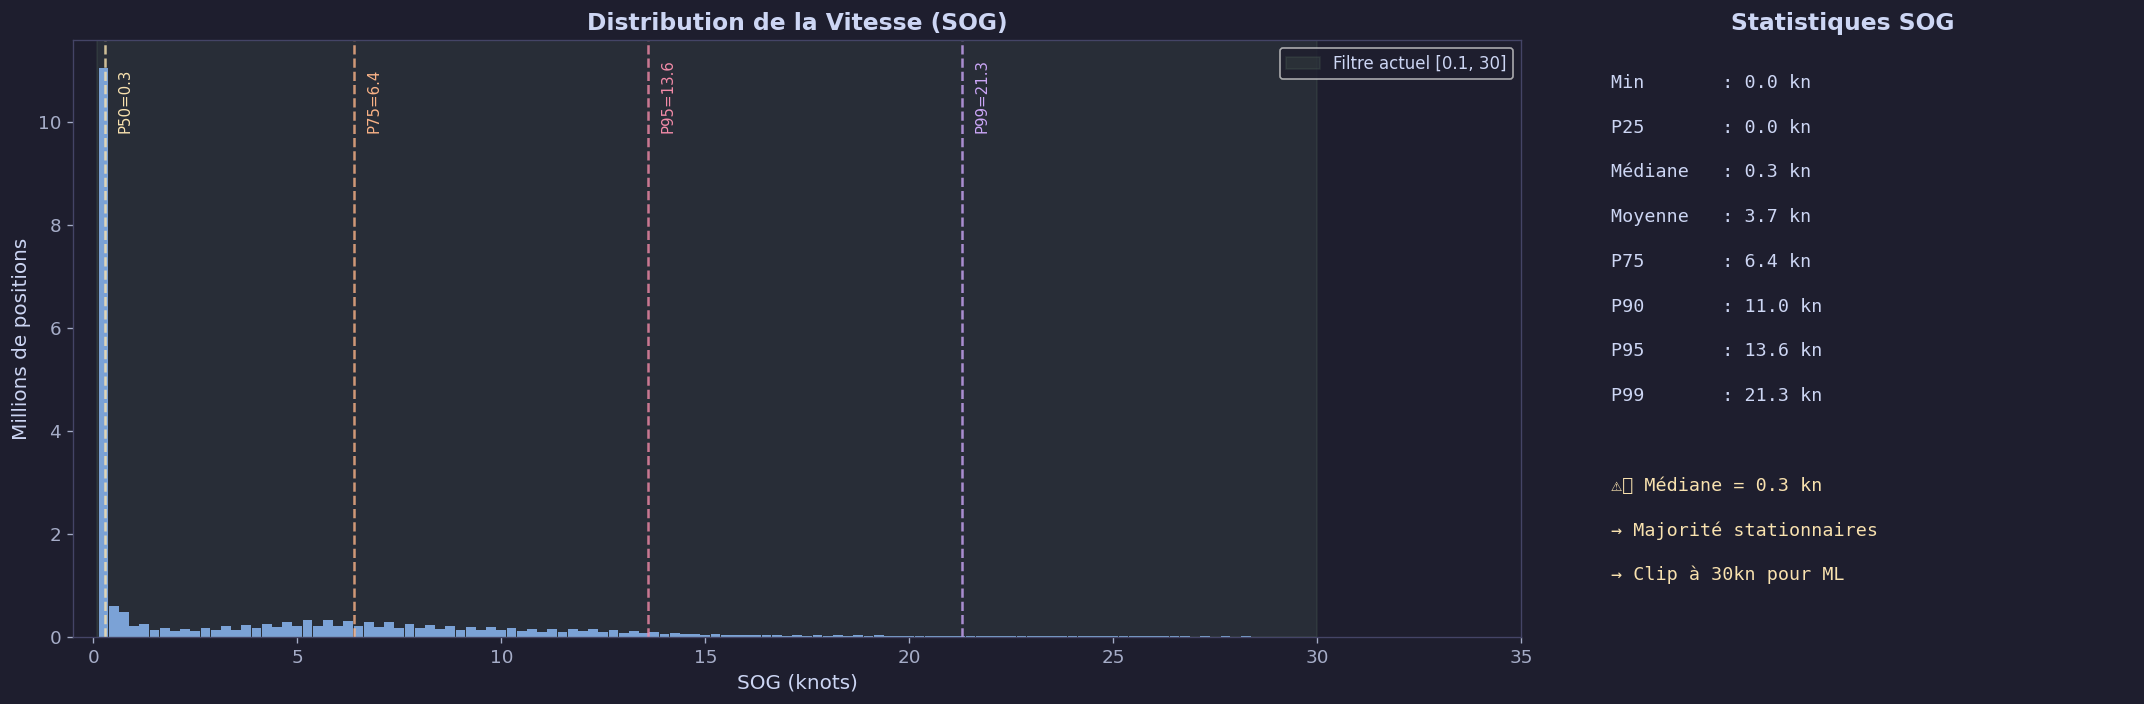

In [ ]:
# ─── Distribution SOG avec percentiles ─────────────────────────
sog_dist = pd.read_sql("""
SELECT width_bucket(sog, 0, 35, 140) as bucket, COUNT(*) as cnt
FROM position_vessel WHERE sog IS NOT NULL AND sog BETWEEN 0 AND 35
GROUP BY bucket ORDER BY bucket
""", engine)
sog_dist['sog_mid'] = sog_dist['bucket'] * 0.25

sog_stats = pd.read_sql("""
SELECT 
  PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY sog) as p25,
  PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY sog) as p50,
  PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY sog) as p75,
  PERCENTILE_CONT(0.90) WITHIN GROUP (ORDER BY sog) as p90,
  PERCENTILE_CONT(0.95) WITHIN GROUP (ORDER BY sog) as p95,
  PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY sog) as p99,
  AVG(sog) as mean
FROM position_vessel WHERE sog IS NOT NULL
""", engine).iloc[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [2.5, 1]})

# Histogramme principal
bars = ax1.bar(sog_dist['sog_mid'], sog_dist['cnt'] / 1e6, width=0.24, 
               color=COLORS['blue'], alpha=0.85, edgecolor='none')
# Zone de filtrage actuel
ax1.axvspan(0.1, 30, alpha=0.08, color=COLORS['green'], label='Filtre actuel [0.1, 30]')
# Percentiles
for label, val, color in [('P50', sog_stats['p50'], COLORS['yellow']),
                           ('P75', sog_stats['p75'], COLORS['peach']),
                           ('P95', sog_stats['p95'], COLORS['red']),
                           ('P99', sog_stats['p99'], COLORS['mauve'])]:
    ax1.axvline(val, color=color, linestyle='--', linewidth=1.5, alpha=0.8)
    ax1.text(val + 0.3, ax1.get_ylim()[1] * 0.85, f'{label}={val:.1f}', color=color, fontsize=9, rotation=90)

ax1.set_xlabel('SOG (knots)', fontsize=12)
ax1.set_ylabel('Millions de positions', fontsize=12)
ax1.set_title('Distribution de la Vitesse (SOG)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_xlim(-0.5, 35)

# Box plot
bp = ax2.boxplot([sog_stats['p25'], sog_stats['p50'], sog_stats['p75']], 
                  vert=True, patch_artist=True)
ax2.clear()
# Tableau stats
stats_text = [
    f"Min       : 0.0 kn",
    f"P25       : {sog_stats['p25']:.1f} kn",
    f"Médiane   : {sog_stats['p50']:.1f} kn",
    f"Moyenne   : {sog_stats['mean']:.1f} kn",
    f"P75       : {sog_stats['p75']:.1f} kn",
    f"P90       : {sog_stats['p90']:.1f} kn",
    f"P95       : {sog_stats['p95']:.1f} kn",
    f"P99       : {sog_stats['p99']:.1f} kn",
    "",
    "⚠️ Médiane = 0.3 kn",
    "→ Majorité stationnaires",
    "→ Clip à 30kn pour ML",
]
for i, line in enumerate(stats_text):
    c = COLORS['yellow'] if '⚠️' in line or '→' in line else '#cdd6f4'
    ax2.text(0.1, 0.92 - i * 0.075, line, fontsize=11, color=c, 
             fontfamily='monospace', transform=ax2.transAxes)
ax2.set_title('Statistiques SOG', fontsize=14, fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()

## 🧭 3. Distribution COG (Cap) — Rose des vents + Vitesse par type de navire

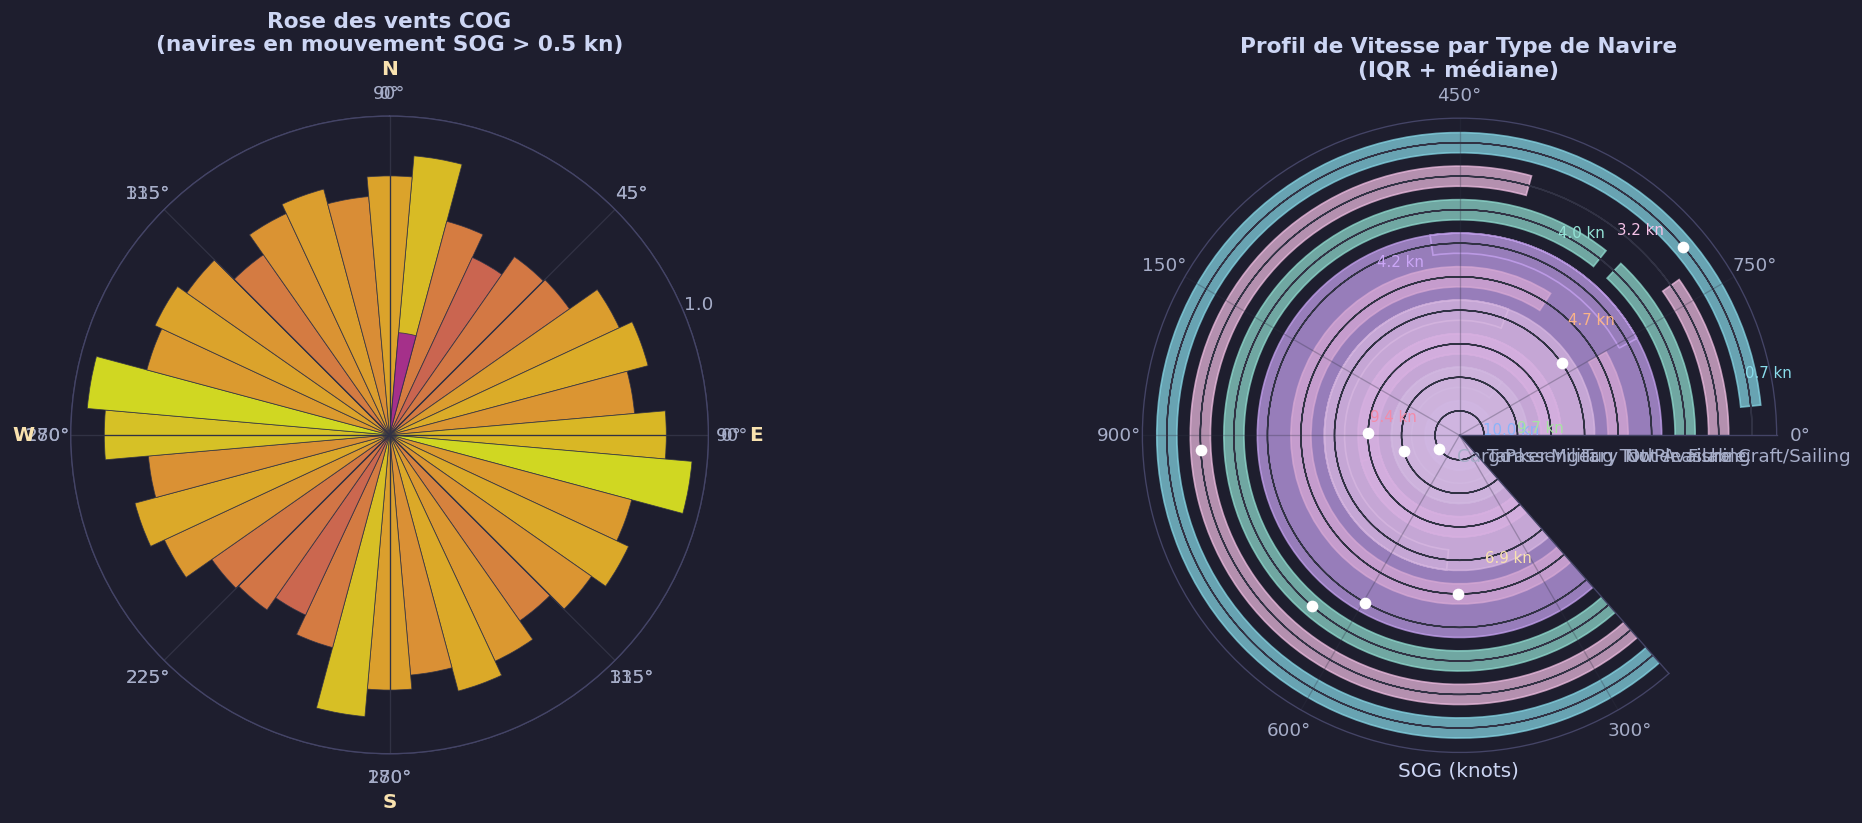

In [ ]:
# ─── Rose des vents COG + Vitesse par type ────────────────────
cog_dist = pd.read_sql("""
SELECT width_bucket(cog, 0, 360, 36) as bucket, COUNT(*) as cnt
FROM position_vessel WHERE cog BETWEEN 0 AND 360 AND sog > 0.5
GROUP BY bucket ORDER BY bucket
""", engine)
cog_dist['angle'] = cog_dist['bucket'] * 10

sog_by_type = pd.read_sql("""
SELECT vt.vessel_group, 
  PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY pv.sog) as p25,
  PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY pv.sog) as median,
  PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY pv.sog) as p75,
  AVG(pv.sog)::numeric(5,2) as mean,
  COUNT(*)::bigint as n
FROM position_vessel pv
JOIN vessel v ON v.id = pv.vessel_id
JOIN vessel_type vt ON v.vessel_type_id = vt.id
WHERE pv.sog > 0 AND pv.sog < 35
GROUP BY vt.vessel_group
HAVING COUNT(*) > 10000
ORDER BY median DESC
""", engine)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7),
                                subplot_kw={'projection': 'polar'})
fig.subplots_adjust(wspace=0.3)

# Rose des vents COG
ax1 = plt.subplot(121, projection='polar')
theta = np.deg2rad(cog_dist['angle'])
width = np.deg2rad(10)
colors_rose = plt.cm.plasma(cog_dist['cnt'] / cog_dist['cnt'].max())
ax1.bar(theta, cog_dist['cnt'] / 1e6, width=width, bottom=0, 
        color=colors_rose, alpha=0.85, edgecolor='#313244', linewidth=0.5)
ax1.set_theta_zero_location('N')
ax1.set_theta_direction(-1)
ax1.set_title('Rose des vents COG\n(navires en mouvement SOG > 0.5 kn)', 
              fontsize=13, fontweight='bold', pad=20)
ax1.set_rticks([])
# Directions cardinales
for angle, label in [(0, 'N'), (90, 'E'), (180, 'S'), (270, 'W')]:
    ax1.text(np.deg2rad(angle), ax1.get_ylim()[1] * 1.15, label,
             ha='center', va='center', fontsize=12, fontweight='bold', color=COLORS['yellow'])

# Box plot horizontal : SOG par type
ax2 = plt.subplot(122)
y_pos = range(len(sog_by_type))
for i, row in sog_by_type.iterrows():
    color = PALETTE[i % len(PALETTE)]
    ax2.barh(i, row['p75'] - row['p25'], left=row['p25'], height=0.6,
             color=color, alpha=0.7, edgecolor=color)
    ax2.plot(row['median'], i, 'o', color='white', markersize=6, zorder=5)
    ax2.text(row['p75'] + 0.3, i, f"{row['median']:.1f} kn", 
             va='center', fontsize=9, color=color)

ax2.set_yticks(range(len(sog_by_type)))
ax2.set_yticklabels(sog_by_type['vessel_group'], fontsize=10)
ax2.set_xlabel('SOG (knots)', fontsize=12)
ax2.set_title('Profil de Vitesse par Type de Navire\n(IQR + médiane)', 
              fontsize=13, fontweight='bold')
ax2.set_xlim(0, 18)
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 🗺️ 4. Carte de densité géographique — Heatmap mondiale

In [ ]:
# ─── Heatmap géographique interactive ──────────────────────────
geo = pd.read_sql("""
SELECT 
  ROUND(ST_Y(geom::geometry)::numeric * 2, 0) / 2.0 as lat,
  ROUND(ST_X(geom::geometry)::numeric * 2, 0) / 2.0 as lon,
  COUNT(*) as density
FROM position_vessel
GROUP BY lat, lon
HAVING COUNT(*) > 50
ORDER BY density DESC
LIMIT 3000
""", engine)

geo['log_density'] = np.log10(geo['density'].clip(lower=1))

fig = px.density_mapbox(
    geo, lat='lat', lon='lon', z='density',
    radius=12,
    center=dict(lat=38, lon=-74),
    zoom=3,
    mapbox_style="carto-darkmatter",
    color_continuous_scale="Turbo",
    title="🗺️ Densité AIS — 22.25M positions (grille 0.5°)",
    height=600,
    width=1000,
)
fig.update_layout(
    template="plotly_dark",
    paper_bgcolor='#1e1e2e',
    plot_bgcolor='#1e1e2e',
    margin=dict(l=20, r=20, t=50, b=20),
)
fig.show()

## 🚢 5. Types de navires — Répartition + Analyse multi-dimensionnelle

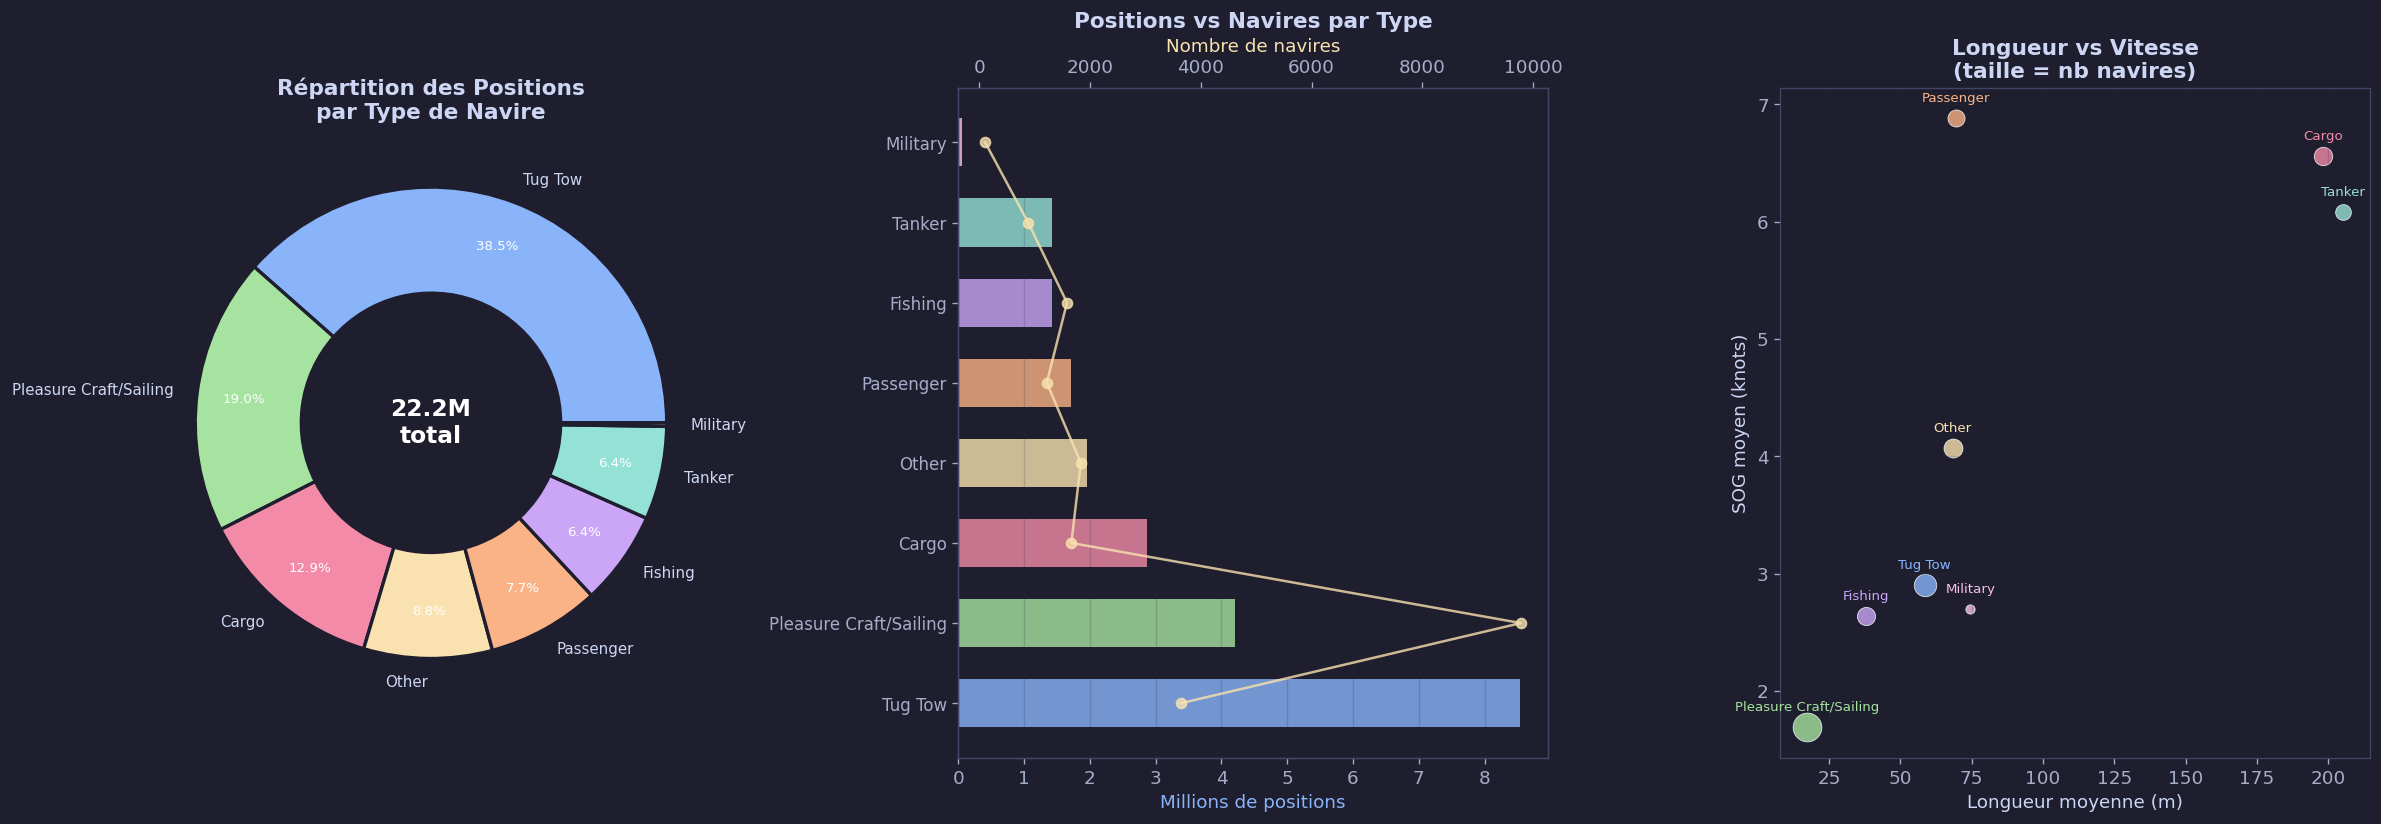

In [ ]:
# ─── Types de navires : Donut + Barres + Dimensions ───────────
vessel_data = pd.read_sql("""
SELECT vt.vessel_group, 
  COUNT(DISTINCT v.id) as n_vessels, 
  COUNT(pv.id)::bigint as n_positions,
  AVG(pv.sog)::numeric(5,2) as avg_sog,
  AVG(v.length)::numeric(6,1) as avg_length,
  AVG(v.width)::numeric(5,1) as avg_width
FROM vessel v
JOIN vessel_type vt ON v.vessel_type_id = vt.id
JOIN position_vessel pv ON pv.vessel_id = v.id
WHERE vt.vessel_group NOT IN ('Not Available')
GROUP BY vt.vessel_group
ORDER BY n_positions DESC
""", engine)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1) Donut : répartition par positions
wedges, texts, autotexts = axes[0].pie(
    vessel_data['n_positions'], labels=vessel_data['vessel_group'],
    autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
    colors=PALETTE[:len(vessel_data)], pctdistance=0.8,
    wedgeprops=dict(width=0.45, edgecolor='#1e1e2e', linewidth=2),
    textprops={'fontsize': 9, 'color': '#cdd6f4'}
)
for at in autotexts:
    at.set_fontsize(8)
    at.set_color('white')
axes[0].set_title('Répartition des Positions\npar Type de Navire', fontsize=13, fontweight='bold')
axes[0].text(0, 0, f"{vessel_data['n_positions'].sum()/1e6:.1f}M\ntotal", 
             ha='center', va='center', fontsize=14, fontweight='bold', color='white')

# 2) Barres horizontales : nombre de navires vs positions
ax2 = axes[1]
y = range(len(vessel_data))
bars = ax2.barh(y, vessel_data['n_positions'] / 1e6, color=PALETTE[:len(vessel_data)], 
                alpha=0.8, edgecolor='none', height=0.6)
ax2t = ax2.twiny()
ax2t.plot(vessel_data['n_vessels'].values, list(y), 'o-', color=COLORS['yellow'], 
          markersize=6, linewidth=1.5, alpha=0.8)
ax2.set_yticks(y)
ax2.set_yticklabels(vessel_data['vessel_group'], fontsize=10)
ax2.set_xlabel('Millions de positions', fontsize=11, color=COLORS['blue'])
ax2t.set_xlabel('Nombre de navires', fontsize=11, color=COLORS['yellow'])
ax2.set_title('Positions vs Navires par Type', fontsize=13, fontweight='bold')
ax2.grid(axis='x', alpha=0.2)

# 3) Scatter : longueur vs vitesse (bulles = nb navires)
ax3 = axes[2]
for i, row in vessel_data.iterrows():
    if pd.notna(row['avg_length']) and row['avg_length'] > 0:
        size = np.sqrt(row['n_vessels']) * 3
        ax3.scatter(row['avg_length'], row['avg_sog'], s=size, 
                    color=PALETTE[i % len(PALETTE)], alpha=0.8, edgecolors='white', linewidth=0.5)
        ax3.annotate(row['vessel_group'], (row['avg_length'], row['avg_sog']),
                     fontsize=8, color=PALETTE[i], ha='center', va='bottom',
                     xytext=(0, 8), textcoords='offset points')
ax3.set_xlabel('Longueur moyenne (m)', fontsize=11)
ax3.set_ylabel('SOG moyen (knots)', fontsize=11)
ax3.set_title('Longueur vs Vitesse\n(taille = nb navires)', fontsize=13, fontweight='bold')
ax3.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## ⏱️ 6. Analyse Temporelle — Activité par heure et par jour + Intervalles

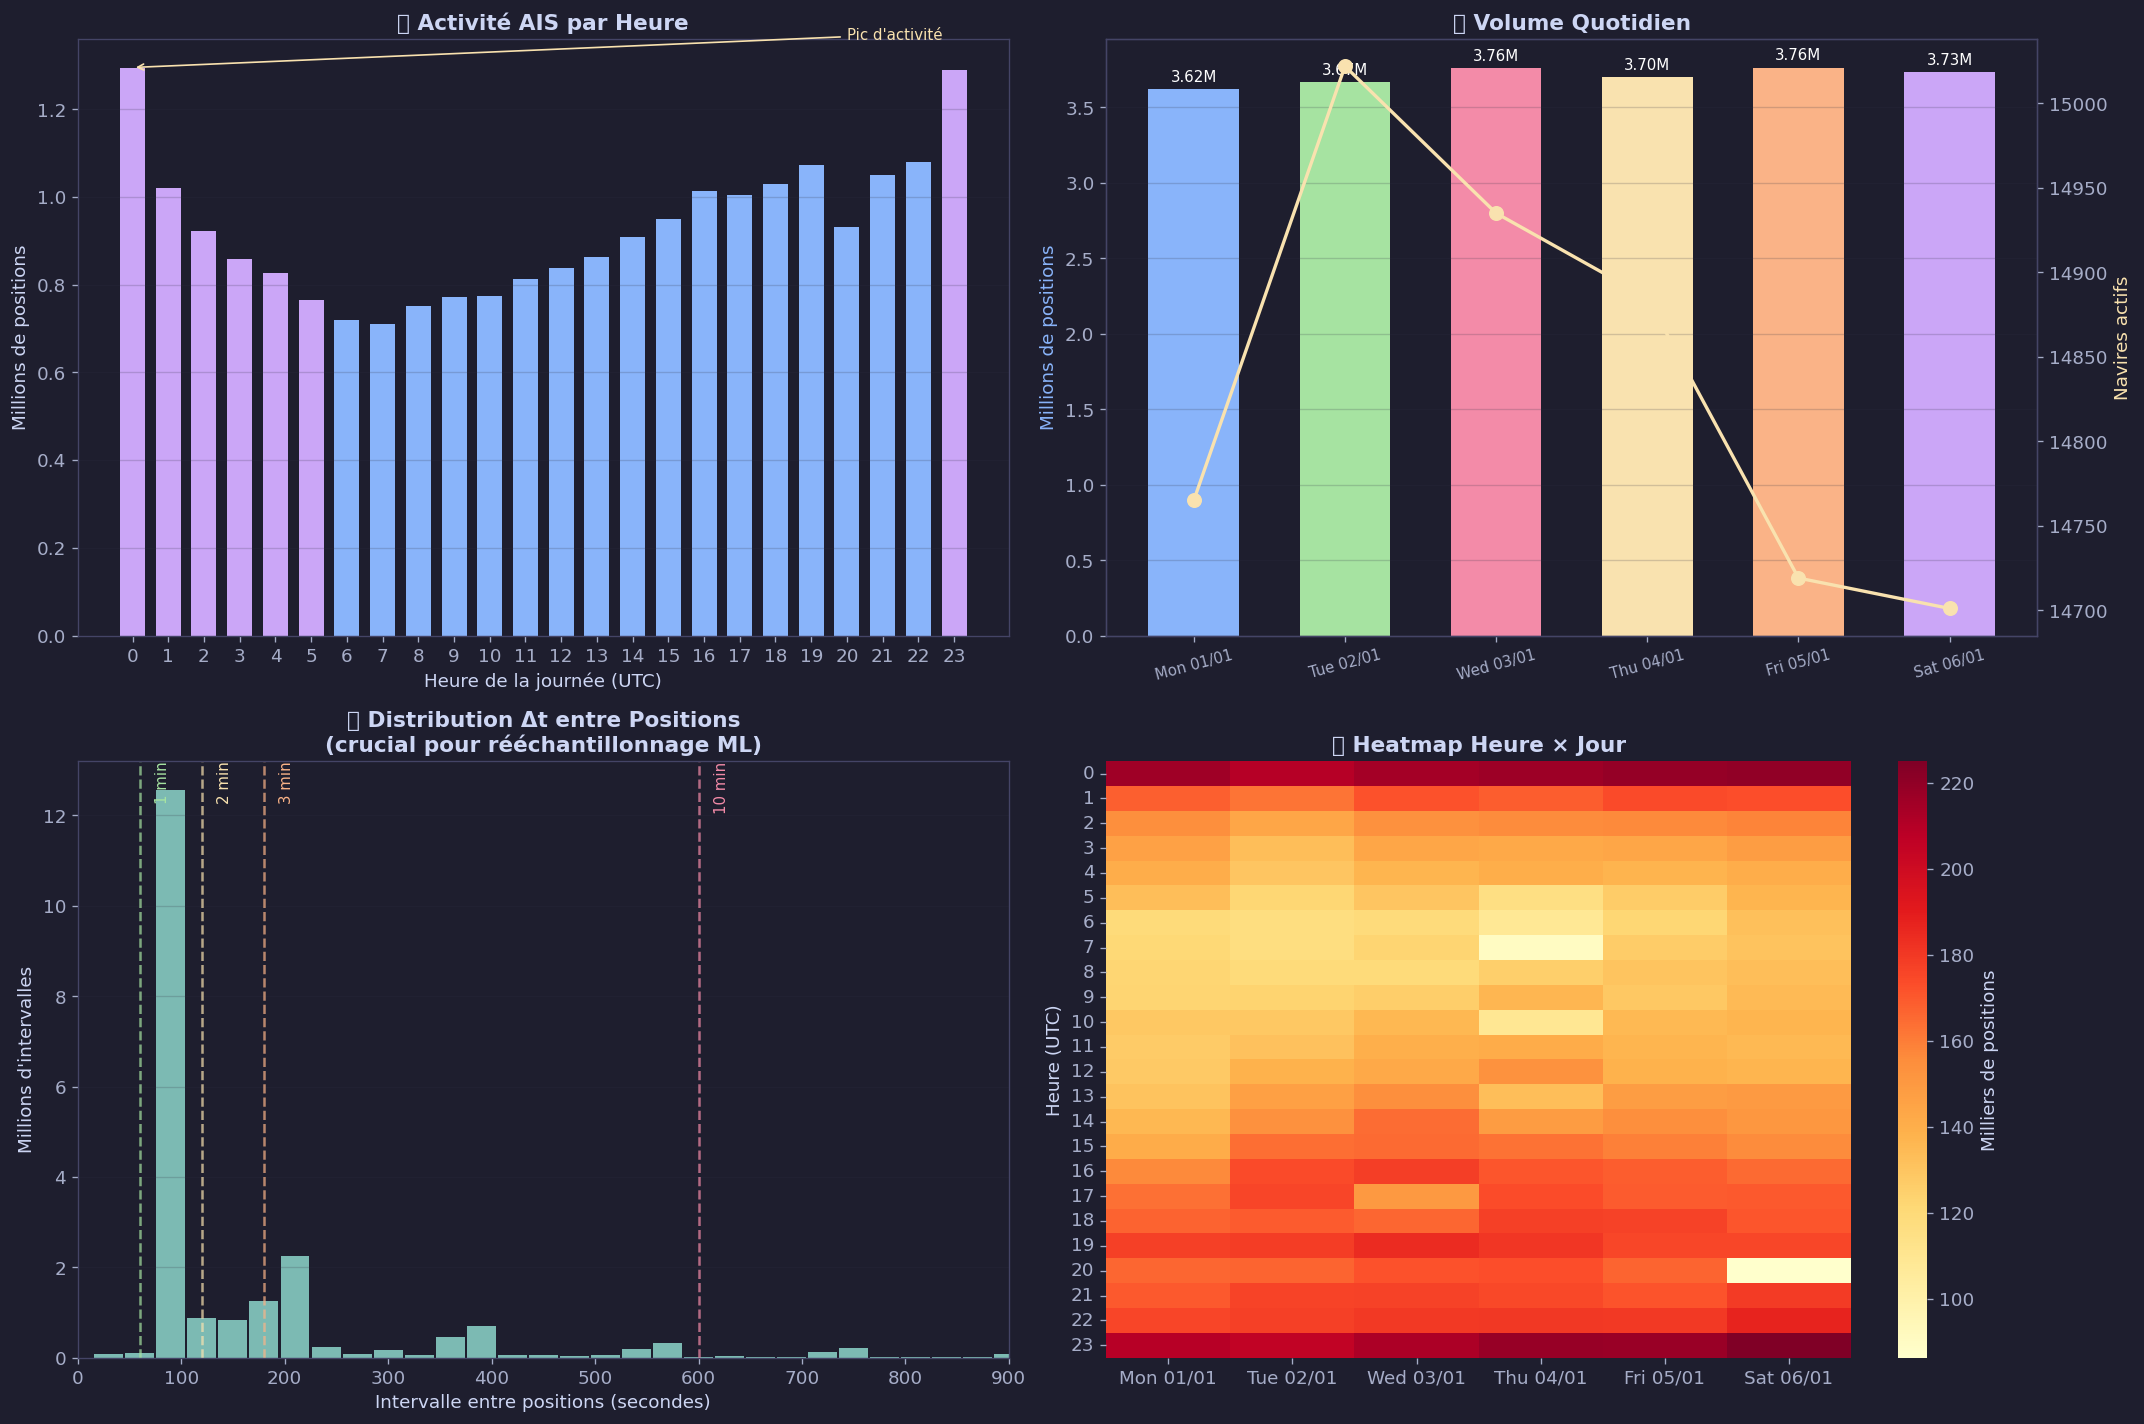

In [ ]:
# ─── Analyse Temporelle ────────────────────────────────────────
hourly = pd.read_sql("""
SELECT EXTRACT(HOUR FROM base_date_time)::int as hour, COUNT(*)::bigint as cnt
FROM position_vessel GROUP BY hour ORDER BY hour
""", engine)

daily = pd.read_sql("""
SELECT DATE(base_date_time) as day, COUNT(*)::bigint as cnt,
  COUNT(DISTINCT vessel_id) as n_vessels,
  AVG(sog)::numeric(5,2) as avg_sog
FROM position_vessel GROUP BY day ORDER BY day
""", engine)

dt_dist = pd.read_sql("""
SELECT width_bucket(dt, 0, 1800, 60) as bucket, COUNT(*)::bigint as cnt
FROM (
  SELECT EXTRACT(EPOCH FROM base_date_time - LAG(base_date_time) 
    OVER (PARTITION BY vessel_id ORDER BY base_date_time)) as dt
  FROM position_vessel
) sub WHERE dt > 0 AND dt < 1800
GROUP BY bucket ORDER BY bucket
""", engine)
dt_dist['seconds'] = dt_dist['bucket'] * 30

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1) Activité par heure (bar chart)
ax = axes[0, 0]
colors_h = [COLORS['blue'] if 6 <= h <= 22 else COLORS['mauve'] for h in hourly['hour']]
ax.bar(hourly['hour'], hourly['cnt'] / 1e6, color=colors_h, edgecolor='none', width=0.7)
ax.set_xlabel('Heure de la journée (UTC)', fontsize=11)
ax.set_ylabel('Millions de positions', fontsize=11)
ax.set_title('📊 Activité AIS par Heure', fontsize=13, fontweight='bold')
ax.set_xticks(range(0, 24))
ax.grid(axis='y', alpha=0.2)
# Annotation
ax.annotate('Pic d\'activité', xy=(hourly.loc[hourly['cnt'].idxmax(), 'hour'], 
            hourly['cnt'].max()/1e6), fontsize=9, color=COLORS['yellow'],
            arrowprops=dict(arrowstyle='->', color=COLORS['yellow']),
            xytext=(20, hourly['cnt'].max()/1e6 * 1.05))

# 2) Volumes quotidiens
ax = axes[0, 1]
colors_d = PALETTE[:len(daily)]
bars = ax.bar(range(len(daily)), daily['cnt'] / 1e6, color=colors_d, edgecolor='none', width=0.6)
ax2 = ax.twinx()
ax2.plot(range(len(daily)), daily['n_vessels'], 'o-', color=COLORS['yellow'], 
         markersize=8, linewidth=2)
ax.set_xticks(range(len(daily)))
ax.set_xticklabels([d.strftime('%a %d/%m') for d in daily['day']], fontsize=9, rotation=15)
ax.set_ylabel('Millions de positions', fontsize=11, color=COLORS['blue'])
ax2.set_ylabel('Navires actifs', fontsize=11, color=COLORS['yellow'])
ax.set_title('📅 Volume Quotidien', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.2)
for i, row in daily.iterrows():
    ax.text(i, row['cnt']/1e6 + 0.05, f"{row['cnt']/1e6:.2f}M", 
            ha='center', fontsize=9, color='white')

# 3) Intervalles entre positions (critique pour ML)
ax = axes[1, 0]
ax.bar(dt_dist['seconds'], dt_dist['cnt'] / 1e6, width=28, 
       color=COLORS['teal'], alpha=0.8, edgecolor='none')
# Lignes de référence
for sec, label, col in [(60, '1 min', COLORS['green']), (120, '2 min', COLORS['yellow']), 
                         (180, '3 min', COLORS['peach']), (600, '10 min', COLORS['red'])]:
    ax.axvline(sec, color=col, linestyle='--', linewidth=1.5, alpha=0.7)
    ax.text(sec + 15, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 1, label, 
            color=col, fontsize=9, rotation=90, va='top')
ax.set_xlabel('Intervalle entre positions (secondes)', fontsize=11)
ax.set_ylabel('Millions d\'intervalles', fontsize=11)
ax.set_title('⏱️ Distribution Δt entre Positions\n(crucial pour rééchantillonnage ML)', 
             fontsize=13, fontweight='bold')
ax.set_xlim(0, 900)
ax.grid(axis='y', alpha=0.2)

# 4) Heatmap heure × jour
ax = axes[1, 1]
hourly_daily = pd.read_sql("""
SELECT DATE(base_date_time) as day, EXTRACT(HOUR FROM base_date_time)::int as hour,
  COUNT(*)::bigint as cnt
FROM position_vessel GROUP BY day, hour
""", engine)
pivot = hourly_daily.pivot(index='hour', columns='day', values='cnt')
pivot.columns = [d.strftime('%a %d/%m') for d in pivot.columns]
sns.heatmap(pivot / 1e3, ax=ax, cmap='YlOrRd', annot=False, 
            cbar_kws={'label': 'Milliers de positions'})
ax.set_title('🗓️ Heatmap Heure × Jour', fontsize=13, fontweight='bold')
ax.set_ylabel('Heure (UTC)')

plt.tight_layout()
plt.show()

## 🚦 7. Statut de Navigation — Distribution & Impact sur la vitesse

NameError: name 'BG' is not defined

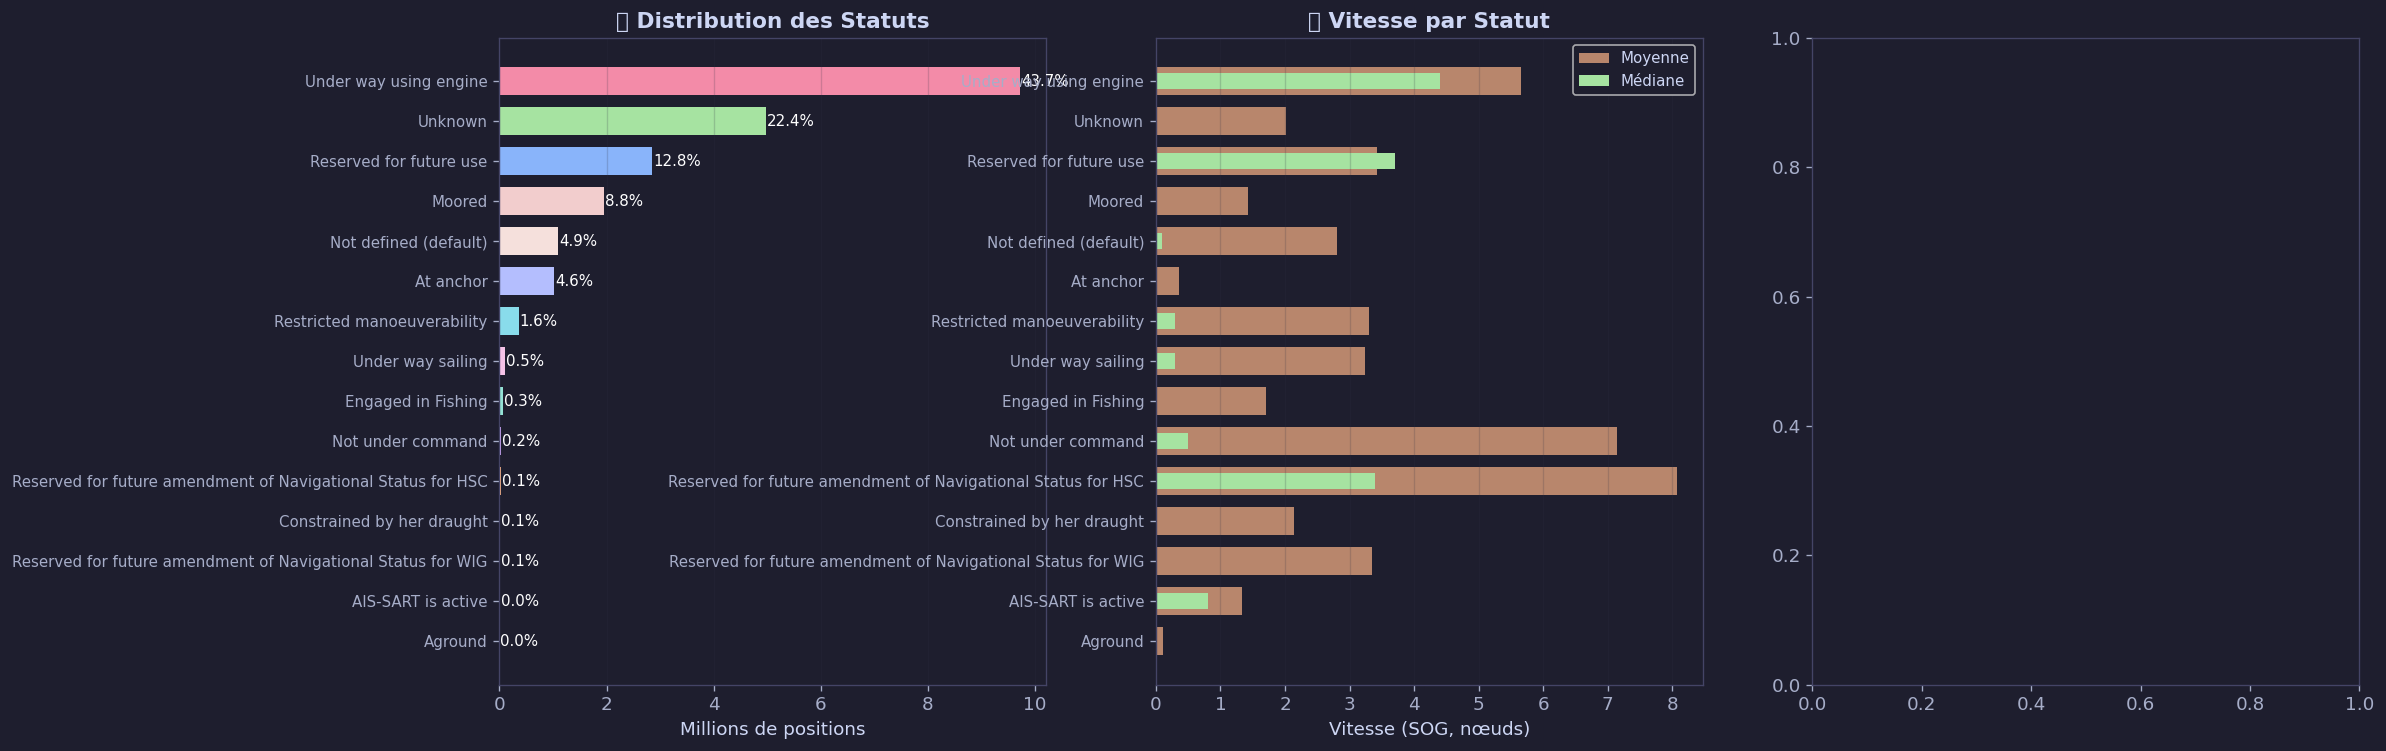

In [ ]:
# ─── Statut de Navigation ──────────────────────────────────────
status = pd.read_sql("""
SELECT vs.description as status_name, COUNT(*)::bigint as cnt,
  AVG(pv.sog)::numeric(5,2) as avg_sog,
  PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY pv.sog)::numeric(5,2) as median_sog,
  AVG(CASE WHEN pv.heading IS NOT NULL THEN pv.heading END)::numeric(5,1) as avg_heading
FROM position_vessel pv
LEFT JOIN vessel_status vs ON pv.status_id = vs.id
GROUP BY vs.description ORDER BY cnt DESC
""", engine)
status['pct'] = status['cnt'] / status['cnt'].sum() * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1) Treemap-style bar chart
ax = axes[0]
status_sorted = status.sort_values('cnt', ascending=True)
colors_s = [PALETTE[i % len(PALETTE)] for i in range(len(status_sorted))]
bars = ax.barh(range(len(status_sorted)), status_sorted['cnt'] / 1e6, 
               color=colors_s, edgecolor='none', height=0.7)
ax.set_yticks(range(len(status_sorted)))
ax.set_yticklabels(status_sorted['status_name'].fillna('Unknown'), fontsize=9)
for i, row in enumerate(status_sorted.itertuples()):
    ax.text(row.cnt/1e6 + 0.02, i, f"{row.pct:.1f}%", va='center', fontsize=9, color='white')
ax.set_xlabel('Millions de positions', fontsize=11)
ax.set_title('📊 Distribution des Statuts', fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.2)

# 2) Vitesse moyenne par statut
ax = axes[1]
ax.barh(range(len(status_sorted)), status_sorted['avg_sog'].astype(float), 
        color=COLORS['peach'], edgecolor='none', height=0.7, alpha=0.7, label='Moyenne')
ax.barh(range(len(status_sorted)), status_sorted['median_sog'].astype(float),
        color=COLORS['green'], edgecolor='none', height=0.4, label='Médiane')
ax.set_yticks(range(len(status_sorted)))
ax.set_yticklabels(status_sorted['status_name'].fillna('Unknown'), fontsize=9)
ax.set_xlabel('Vitesse (SOG, nœuds)', fontsize=11)
ax.set_title('🚀 Vitesse par Statut', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='x', alpha=0.2)

# 3) Pie chart top statuts
ax = axes[2]
top_status = status.head(6)
others = pd.DataFrame({'status_name': ['Autres'], 
                        'cnt': [status.iloc[6:]['cnt'].sum() if len(status) > 6 else 0]})
pie_data = pd.concat([top_status[['status_name', 'cnt']], others]).reset_index(drop=True)
pie_data = pie_data[pie_data['cnt'] > 0]
wedges, texts, autotexts = ax.pie(pie_data['cnt'], labels=pie_data['status_name'], 
                                   autopct='%1.1f%%', colors=PALETTE[:len(pie_data)],
                                   textprops={'color': 'white', 'fontsize': 9},
                                   wedgeprops={'edgecolor': BG, 'linewidth': 2},
                                   pctdistance=0.75)
ax.set_title('🥧 Répartition des Statuts', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# Table de synthèse
print(f"\n{'─'*80}")
print(f"{'Statut':<30} {'Count':>12} {'%':>8} {'SOG moy':>10} {'SOG méd':>10}")
print(f"{'─'*80}")
for _, r in status.iterrows():
    name = r['status_name'] if r['status_name'] else 'Unknown'
    print(f"{name:<30} {r['cnt']:>12,} {r['pct']:>7.1f}% {float(r['avg_sog']):>9.2f} {float(r['median_sog']):>9.2f}")
print(f"{'─'*80}")

## 🧭 8. Heading vs COG — Corrélation & Angle de Dérive

NameError: name 'BG' is not defined

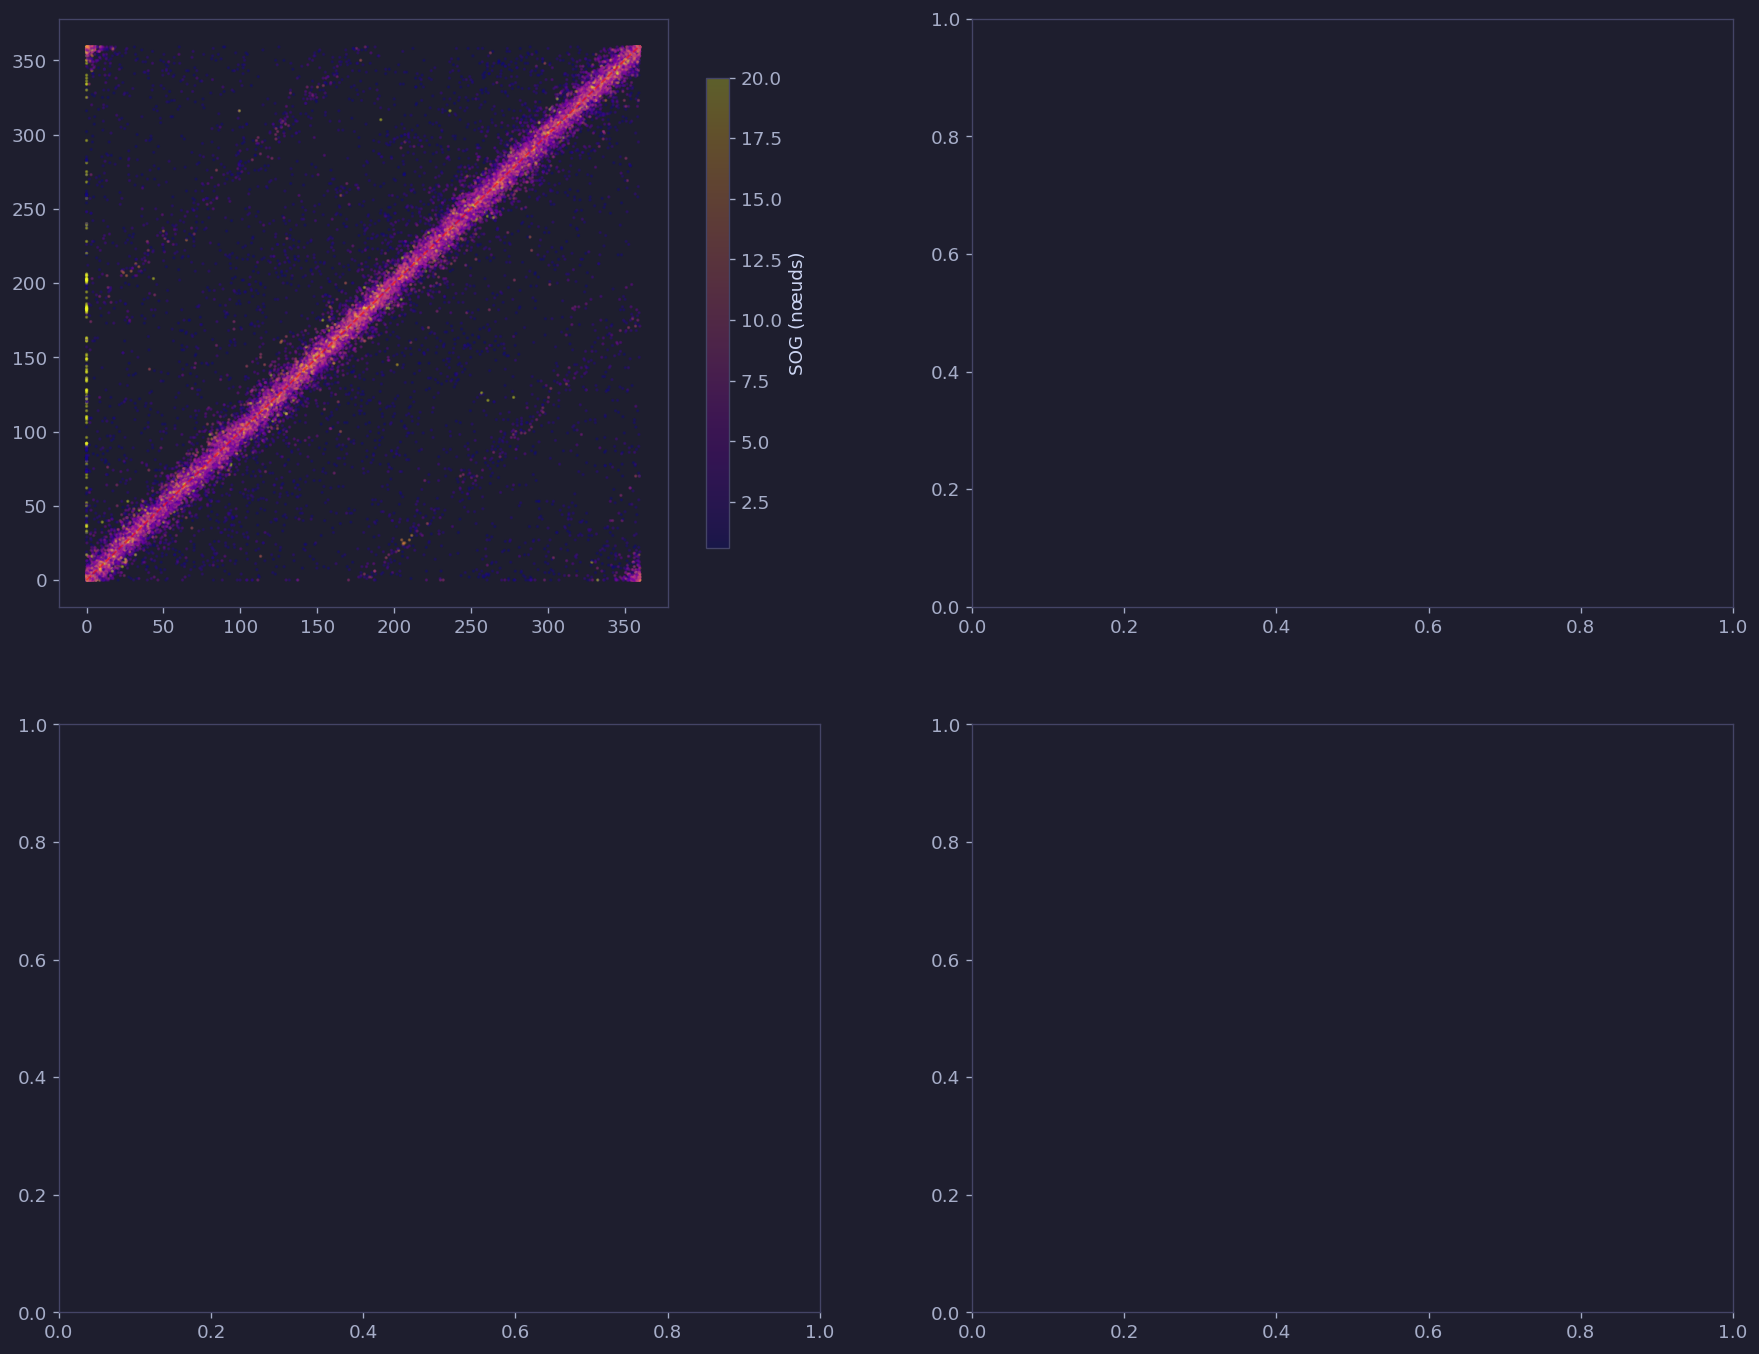

In [ ]:
# ─── Heading vs COG ───────────────────────────────────────────
heading_cog = pd.read_sql("""
SELECT heading, MOD(cog::numeric, 360)::float as cog_norm, sog,
  CASE WHEN heading IS NOT NULL AND cog IS NOT NULL 
    THEN LEAST(ABS(heading - MOD(cog::numeric, 360)), 360 - ABS(heading - MOD(cog::numeric, 360)))
  END as drift_angle
FROM position_vessel
WHERE heading IS NOT NULL AND heading < 360 AND cog IS NOT NULL AND sog > 0.5
ORDER BY RANDOM() LIMIT 50000
""", engine)

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1) Scatter Heading vs COG
ax = axes[0, 0]
sc = ax.scatter(heading_cog['cog_norm'], heading_cog['heading'], 
                c=heading_cog['sog'].clip(0, 20), cmap='plasma', 
                s=1, alpha=0.3, rasterized=True)
ax.plot([0, 360], [0, 360], 'r--', linewidth=1, alpha=0.5, label='Parfaite corrélation')
plt.colorbar(sc, ax=ax, label='SOG (nœuds)', shrink=0.8)
corr = heading_cog[['heading', 'cog_norm']].corr().iloc[0, 1]
ax.text(0.05, 0.95, f'r = {corr:.3f}', transform=ax.transAxes, 
        fontsize=12, fontweight='bold', color=COLORS['green'], va='top',
        bbox=dict(boxstyle='round', facecolor=BG, alpha=0.8, edgecolor=COLORS['green']))
ax.set_xlabel('COG (°)', fontsize=11)
ax.set_ylabel('Heading (°)', fontsize=11)
ax.set_title('🧭 Heading vs COG (couleur = SOG)', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.set_xlim(0, 360)
ax.set_ylim(0, 360)

# 2) Distribution de l'angle de dérive
ax = axes[0, 1]
drift = heading_cog['drift_angle'].dropna()
ax.hist(drift, bins=90, range=(0, 180), color=COLORS['teal'], edgecolor='none', alpha=0.8)
ax.axvline(drift.median(), color=COLORS['yellow'], linewidth=2, linestyle='--', 
           label=f'Médiane: {drift.median():.1f}°')
ax.axvline(drift.mean(), color=COLORS['red'], linewidth=2, linestyle='--',
           label=f'Moyenne: {drift.mean():.1f}°')
ax.set_xlabel('Angle de dérive |Heading - COG| (°)', fontsize=11)
ax.set_ylabel('Nombre de positions', fontsize=11)
ax.set_title('🌊 Distribution de l\'Angle de Dérive', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.2)

# 3) Drift angle vs SOG
ax = axes[1, 0]
bins_sog = pd.cut(heading_cog['sog'].clip(0, 25), bins=25)
drift_by_sog = heading_cog.groupby(bins_sog, observed=True)['drift_angle'].agg(['mean', 'median', 'std'])
x = range(len(drift_by_sog))
ax.fill_between(x, drift_by_sog['mean'] - drift_by_sog['std'], 
                drift_by_sog['mean'] + drift_by_sog['std'], 
                alpha=0.2, color=COLORS['blue'])
ax.plot(x, drift_by_sog['mean'], 'o-', color=COLORS['blue'], linewidth=2, 
        markersize=5, label='Moyenne ± σ')
ax.plot(x, drift_by_sog['median'], 's-', color=COLORS['green'], linewidth=2,
        markersize=5, label='Médiane')
ax.set_xticks(x[::5])
ax.set_xticklabels([f'{i*1:.0f}' for i in range(0, len(x), 5)], fontsize=9)
ax.set_xlabel('SOG (nœuds)', fontsize=11)
ax.set_ylabel('Angle de dérive (°)', fontsize=11)
ax.set_title('🔗 Dérive vs Vitesse\n(les navires lents dérivent plus)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.2)

# 4) Heading availability by vessel type
heading_avail = pd.read_sql("""
SELECT vt.description as vessel_type_name,
  COUNT(CASE WHEN pv.heading IS NOT NULL THEN 1 END)::float / COUNT(*)::float * 100 as pct_heading,
  COUNT(*)::bigint as cnt
FROM position_vessel pv
JOIN vessel v ON pv.vessel_id = v.id
JOIN vessel_type vt ON v.vessel_type_id = vt.id
GROUP BY vt.description
HAVING COUNT(*) > 1000
ORDER BY pct_heading DESC
""", engine)

ax = axes[1, 1]
colors_ha = [COLORS['green'] if p > 70 else COLORS['yellow'] if p > 40 else COLORS['red'] 
             for p in heading_avail['pct_heading']]
bars = ax.barh(range(len(heading_avail)), heading_avail['pct_heading'], 
               color=colors_ha, edgecolor='none', height=0.7)
ax.set_yticks(range(len(heading_avail)))
ax.set_yticklabels(heading_avail['vessel_type_name'], fontsize=8)
ax.set_xlabel('% positions avec Heading', fontsize=11)
ax.set_title('📡 Disponibilité du Heading par Type\n(🟢 >70% 🟡 40-70% 🔴 <40%)', 
             fontsize=13, fontweight='bold')
ax.axvline(50, color='white', linestyle=':', alpha=0.3)
for i, row in enumerate(heading_avail.itertuples()):
    ax.text(row.pct_heading + 1, i, f"{row.pct_heading:.0f}%", 
            va='center', fontsize=9, color='white')
ax.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

# Insight ML
print("\n💡 INSIGHT ML:")
print(f"   • Corrélation Heading↔COG = {corr:.3f} → feature complémentaire utile")
print(f"   • Angle de dérive médian = {drift.median():.1f}° (moyen: {drift.mean():.1f}°)")
print(f"   • À basse vitesse (<2 kn), heading est très bruité → masquer si SOG < 0.5")
print(f"   • {(heading_avail['pct_heading'] < 50).sum()} types ont <50% de heading → imputation nécessaire")

## 📐 9. Dimensions des Navires — Longueur, Largeur, Tirant d'eau

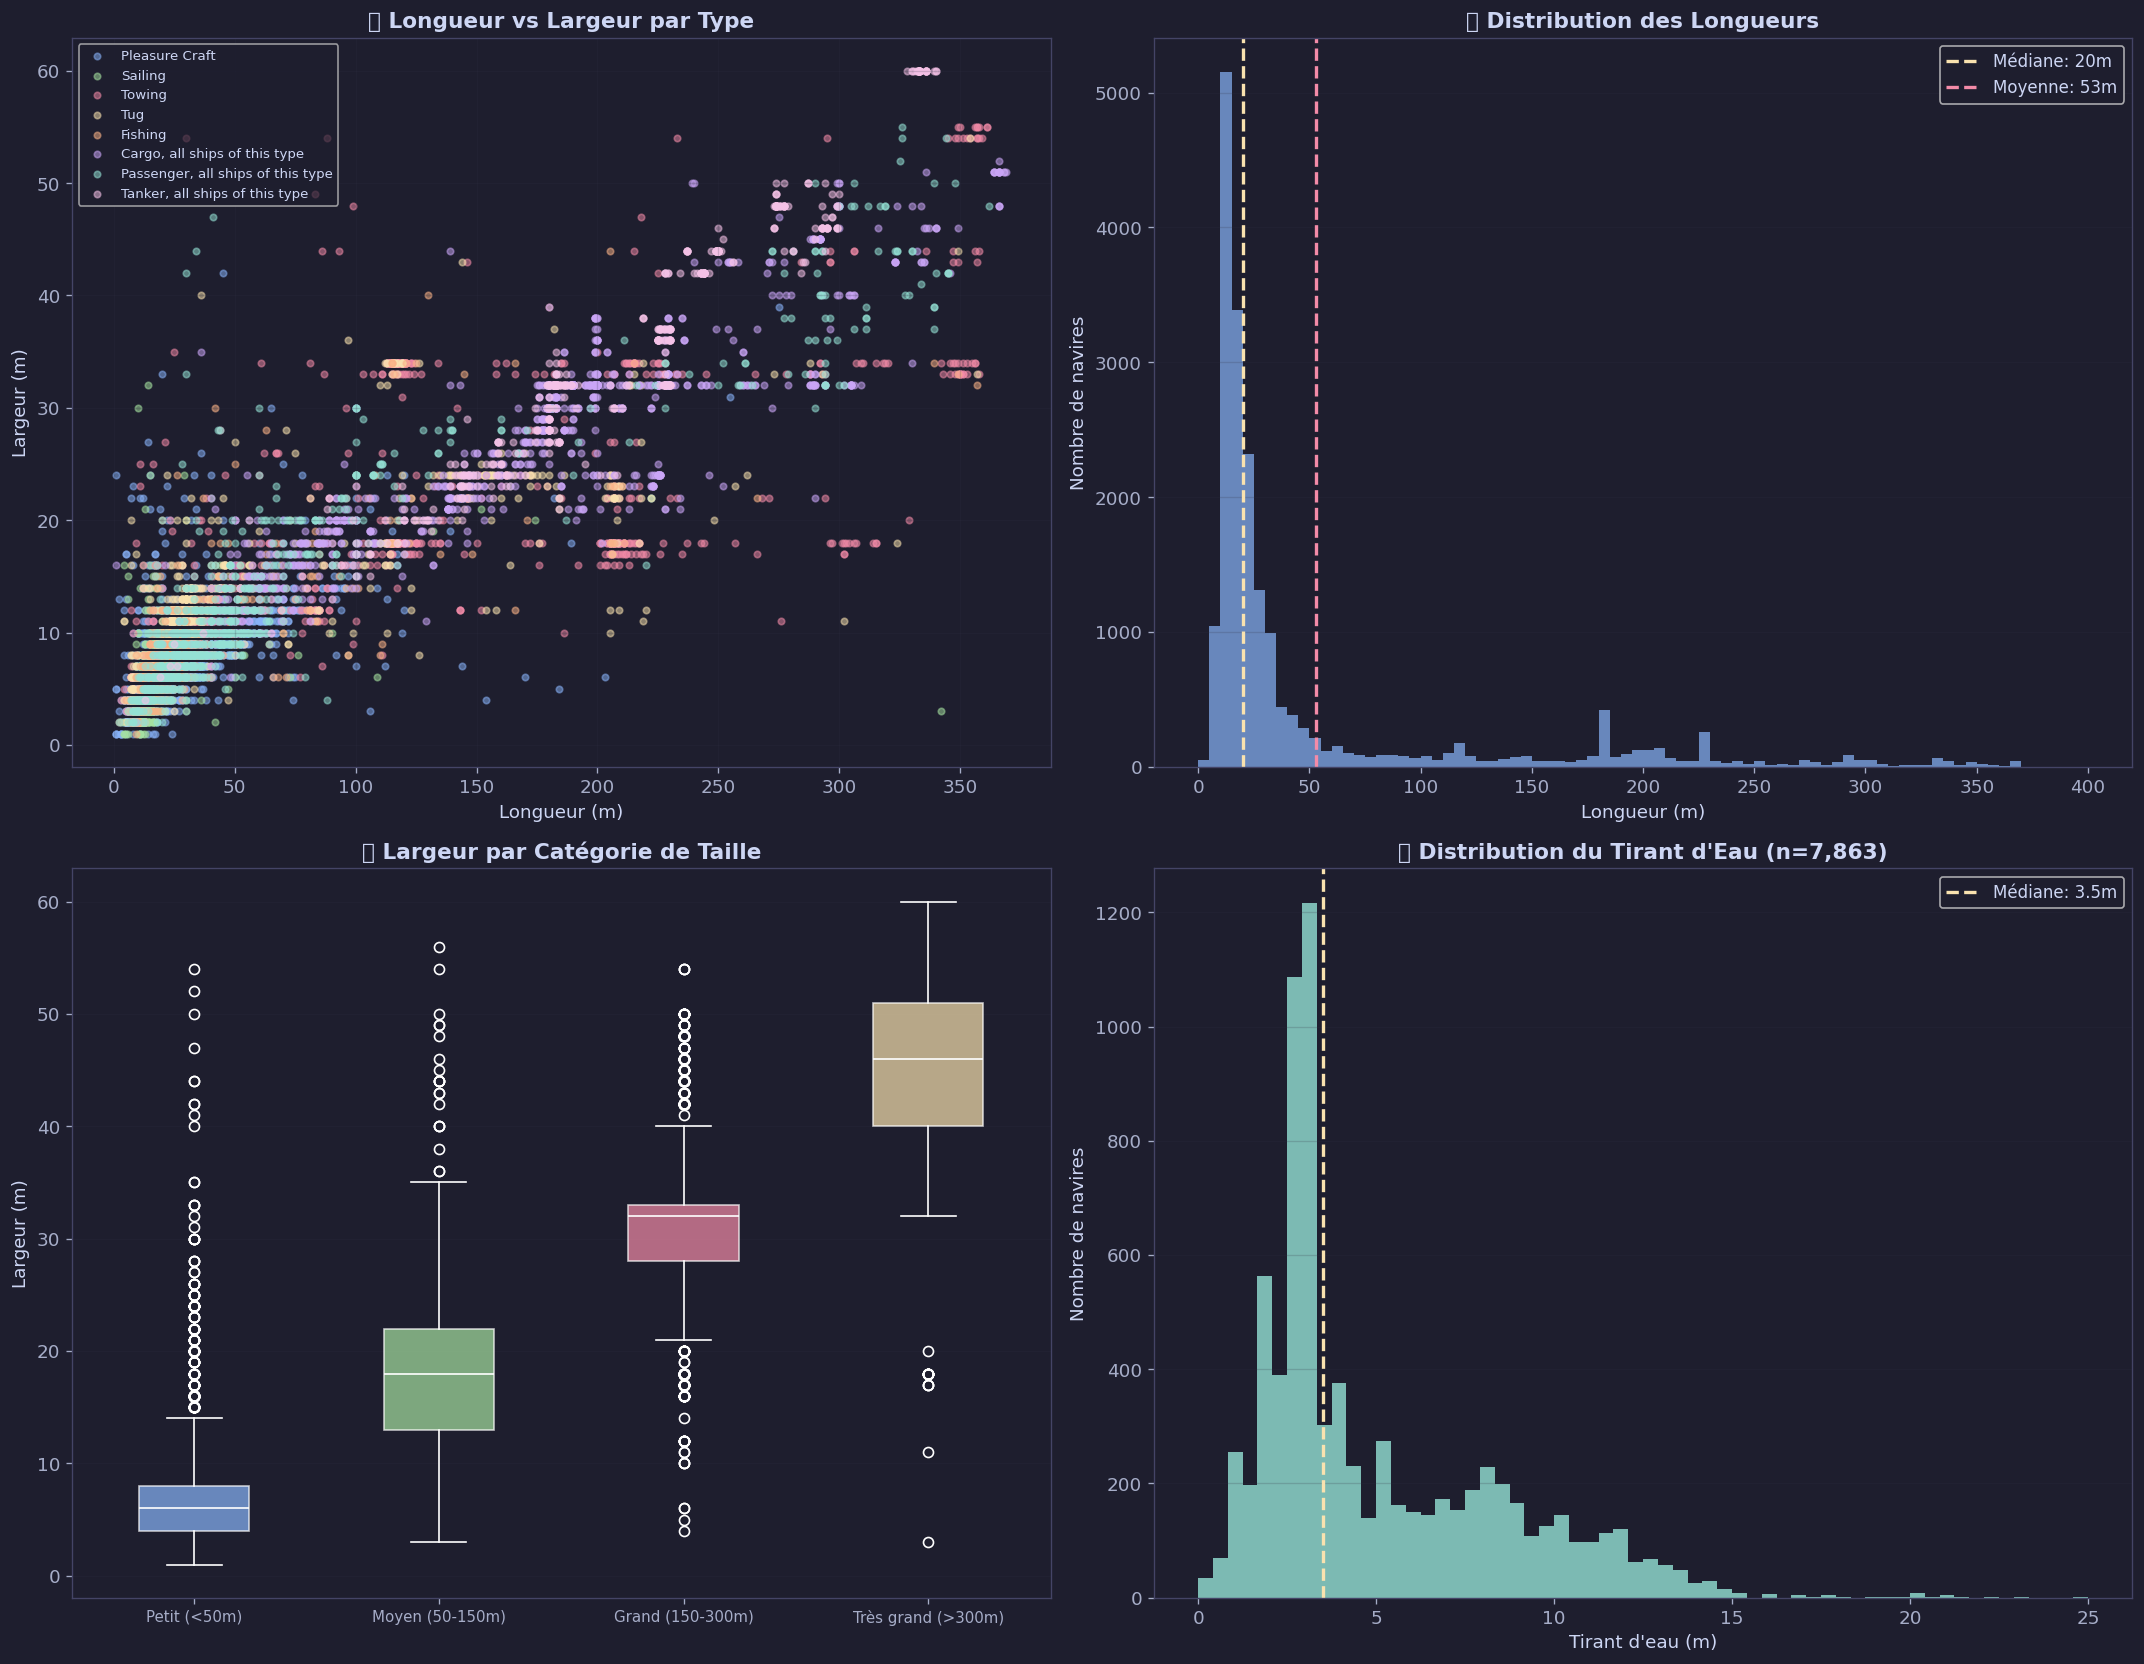


📐 DIMENSIONS — Résumé:
   • Navires avec dimensions: 19,776
   • Longueur: 1 – 369m (méd: 20m)
   • Largeur:  1 – 60m (méd: 7m)
   • Tirant:   0.1 – 25.0m (méd: 3.5m)
   • Petit (<50m): 15,367 navires (77.7%)
   • Moyen (50-150m): 1,866 navires (9.4%)
   • Grand (150-300m): 2,176 navires (11.0%)
   • Très grand (>300m): 367 navires (1.9%)


In [ ]:
# ─── Dimensions des Navires ────────────────────────────────────
dims = pd.read_sql("""
SELECT v.length, v.width, v.draft, vt.description as vessel_type_name,
  CASE 
    WHEN v.length < 50 THEN 'Petit (<50m)'
    WHEN v.length < 150 THEN 'Moyen (50-150m)'
    WHEN v.length < 300 THEN 'Grand (150-300m)'
    ELSE 'Très grand (>300m)'
  END as size_cat
FROM vessel v
JOIN vessel_type vt ON v.vessel_type_id = vt.id
WHERE v.length > 0 AND v.width > 0
""", engine)

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1) Scatter Length vs Width (coloré par type)
ax = axes[0, 0]
top_types = dims['vessel_type_name'].value_counts().head(8).index
for i, vtype in enumerate(top_types):
    subset = dims[dims['vessel_type_name'] == vtype]
    ax.scatter(subset['length'], subset['width'], s=15, alpha=0.5, 
               color=PALETTE[i], label=vtype, rasterized=True)
ax.set_xlabel('Longueur (m)', fontsize=11)
ax.set_ylabel('Largeur (m)', fontsize=11)
ax.set_title('📏 Longueur vs Largeur par Type', fontsize=13, fontweight='bold')
ax.legend(fontsize=8, loc='upper left', framealpha=0.7)
ax.grid(alpha=0.2)

# 2) Distribution des longueurs
ax = axes[0, 1]
ax.hist(dims['length'], bins=80, range=(0, 400), color=COLORS['blue'], 
        edgecolor='none', alpha=0.7)
ax.axvline(dims['length'].median(), color=COLORS['yellow'], linewidth=2, 
           linestyle='--', label=f"Médiane: {dims['length'].median():.0f}m")
ax.axvline(dims['length'].mean(), color=COLORS['red'], linewidth=2, 
           linestyle='--', label=f"Moyenne: {dims['length'].mean():.0f}m")
ax.set_xlabel('Longueur (m)', fontsize=11)
ax.set_ylabel('Nombre de navires', fontsize=11)
ax.set_title('📊 Distribution des Longueurs', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.2)

# 3) Box plots par catégorie de taille
ax = axes[1, 0]
size_order = ['Petit (<50m)', 'Moyen (50-150m)', 'Grand (150-300m)', 'Très grand (>300m)']
data_box = [dims[dims['size_cat'] == cat]['width'].dropna().values for cat in size_order if cat in dims['size_cat'].values]
labels_box = [cat for cat in size_order if cat in dims['size_cat'].values]
bp = ax.boxplot(data_box, labels=labels_box, patch_artist=True, vert=True)
for patch, color in zip(bp['boxes'], PALETTE):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for element in ['whiskers', 'caps', 'medians']:
    for item in bp[element]:
        item.set_color('white')
ax.set_ylabel('Largeur (m)', fontsize=11)
ax.set_title('📦 Largeur par Catégorie de Taille', fontsize=13, fontweight='bold')
ax.tick_params(axis='x', labelsize=9)
ax.grid(axis='y', alpha=0.2)

# 4) Draft distribution (tirant d'eau)
ax = axes[1, 1]
draft_data = dims[dims['draft'] > 0]['draft']
if len(draft_data) > 0:
    ax.hist(draft_data, bins=60, range=(0, 25), color=COLORS['teal'], edgecolor='none', alpha=0.8)
    ax.axvline(draft_data.median(), color=COLORS['yellow'], linewidth=2, linestyle='--',
               label=f"Médiane: {draft_data.median():.1f}m")
    ax.set_xlabel('Tirant d\'eau (m)', fontsize=11)
    ax.set_ylabel('Nombre de navires', fontsize=11)
    ax.set_title(f'🌊 Distribution du Tirant d\'Eau (n={len(draft_data):,})', 
                 fontsize=13, fontweight='bold')
    ax.legend(fontsize=10)
else:
    ax.text(0.5, 0.5, 'Pas de données de tirant d\'eau', ha='center', va='center',
            fontsize=14, color=COLORS['red'], transform=ax.transAxes)
    ax.set_title('🌊 Tirant d\'Eau — Données manquantes', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

# Stats résumé
print(f"\n📐 DIMENSIONS — Résumé:")
print(f"   • Navires avec dimensions: {len(dims):,}")
print(f"   • Longueur: {dims['length'].min():.0f} – {dims['length'].max():.0f}m (méd: {dims['length'].median():.0f}m)")
print(f"   • Largeur:  {dims['width'].min():.0f} – {dims['width'].max():.0f}m (méd: {dims['width'].median():.0f}m)")
if len(draft_data) > 0:
    print(f"   • Tirant:   {draft_data.min():.1f} – {draft_data.max():.1f}m (méd: {draft_data.median():.1f}m)")
for cat in size_order:
    cnt = (dims['size_cat'] == cat).sum()
    print(f"   • {cat}: {cnt:,} navires ({cnt/len(dims)*100:.1f}%)")

## 🔍 10. Qualité des Données — Valeurs manquantes, Outliers & Anomalies

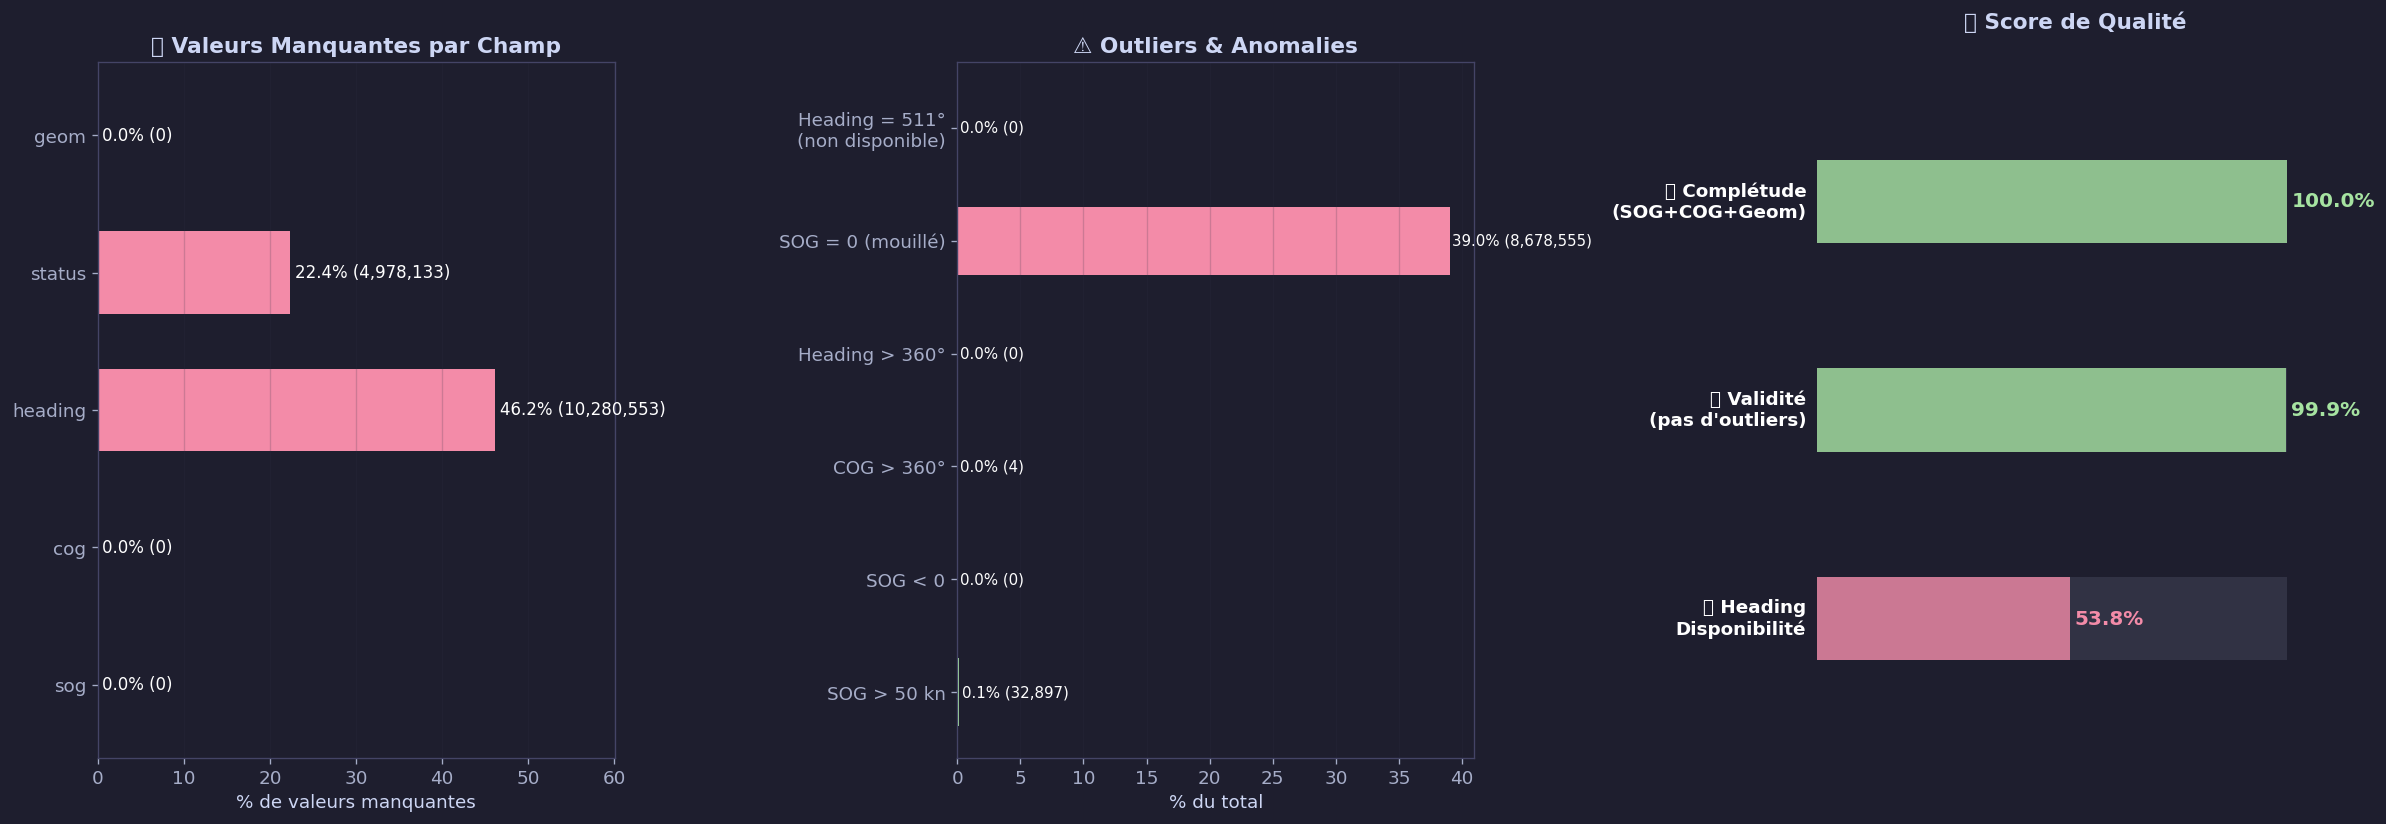

In [ ]:
# ─── Qualité des Données ──────────────────────────────────────
quality = pd.read_sql("""
SELECT
  COUNT(*)::bigint as total,
  COUNT(CASE WHEN sog IS NULL THEN 1 END)::bigint as null_sog,
  COUNT(CASE WHEN cog IS NULL THEN 1 END)::bigint as null_cog,
  COUNT(CASE WHEN heading IS NULL THEN 1 END)::bigint as null_heading,
  COUNT(CASE WHEN status_id IS NULL THEN 1 END)::bigint as null_status,
  COUNT(CASE WHEN geom IS NULL THEN 1 END)::bigint as null_geom,
  COUNT(CASE WHEN sog > 50 THEN 1 END)::bigint as outlier_sog_high,
  COUNT(CASE WHEN sog < 0 THEN 1 END)::bigint as outlier_sog_neg,
  COUNT(CASE WHEN cog > 360 THEN 1 END)::bigint as outlier_cog,
  COUNT(CASE WHEN heading > 360 THEN 1 END)::bigint as outlier_heading,
  COUNT(CASE WHEN sog = 0 THEN 1 END)::bigint as sog_zero,
  COUNT(CASE WHEN heading = 511 THEN 1 END)::bigint as heading_511
FROM position_vessel
""", engine).iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1) Missing values bar chart
ax = axes[0]
fields = ['sog', 'cog', 'heading', 'status', 'geom']
null_counts = [quality['null_sog'], quality['null_cog'], quality['null_heading'], 
               quality['null_status'], quality['null_geom']]
null_pcts = [n / quality['total'] * 100 for n in null_counts]
colors_q = [COLORS['green'] if p < 1 else COLORS['yellow'] if p < 20 else COLORS['red'] for p in null_pcts]

bars = ax.barh(fields, null_pcts, color=colors_q, edgecolor='none', height=0.6)
for i, (pct, cnt) in enumerate(zip(null_pcts, null_counts)):
    ax.text(pct + 0.5, i, f"{pct:.1f}% ({cnt:,.0f})", va='center', fontsize=10, color='white')
ax.set_xlabel('% de valeurs manquantes', fontsize=11)
ax.set_title('❌ Valeurs Manquantes par Champ', fontsize=13, fontweight='bold')
ax.set_xlim(0, max(null_pcts) * 1.3 if max(null_pcts) > 0 else 5)
ax.grid(axis='x', alpha=0.2)

# 2) Outliers & anomalies
ax = axes[1]
anomalies = {
    'SOG > 50 kn': quality['outlier_sog_high'],
    'SOG < 0': quality['outlier_sog_neg'],
    'COG > 360°': quality['outlier_cog'],
    'Heading > 360°': quality['outlier_heading'],
    'SOG = 0 (mouillé)': quality['sog_zero'],
    'Heading = 511°\n(non disponible)': quality['heading_511']
}
anom_names = list(anomalies.keys())
anom_vals = [float(v) for v in anomalies.values()]
anom_pcts = [v / float(quality['total']) * 100 for v in anom_vals]

colors_a = [COLORS['red'] if p > 5 else COLORS['peach'] if p > 1 else COLORS['green'] for p in anom_pcts]
bars = ax.barh(anom_names, anom_pcts, color=colors_a, edgecolor='none', height=0.6)
for i, (pct, cnt) in enumerate(zip(anom_pcts, anom_vals)):
    ax.text(pct + 0.2, i, f"{pct:.1f}% ({cnt:,.0f})", va='center', fontsize=9, color='white')
ax.set_xlabel('% du total', fontsize=11)
ax.set_title('⚠️ Outliers & Anomalies', fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.2)

# 3) Data quality score card
ax = axes[2]
ax.axis('off')
total = float(quality['total'])
completeness = (1 - (float(quality['null_sog']) + float(quality['null_cog']) + 
                      float(quality['null_geom'])) / (total * 3)) * 100
validity = (1 - (float(quality['outlier_sog_high']) + float(quality['outlier_cog']) + 
                  float(quality['outlier_sog_neg'])) / total) * 100
heading_quality = (1 - float(quality['null_heading']) / total) * 100

scores = [('Complétude\n(SOG+COG+Geom)', completeness), 
          ('Validité\n(pas d\'outliers)', validity),
          ('Heading\nDisponibilité', heading_quality)]

for i, (label, score) in enumerate(scores):
    y = 0.8 - i * 0.3
    color = COLORS['green'] if score > 90 else COLORS['yellow'] if score > 70 else COLORS['red']
    emoji = '🟢' if score > 90 else '🟡' if score > 70 else '🔴'
    # Score bar background
    ax.barh(y, 100, height=0.12, color='#313244', left=0)
    ax.barh(y, score, height=0.12, color=color, left=0, alpha=0.8)
    ax.text(-0.02, y, f"{emoji} {label}", ha='right', va='center', fontsize=11, 
            fontweight='bold', color='white', transform=ax.get_yaxis_transform())
    ax.text(score + 1, y, f"{score:.1f}%", ha='left', va='center', fontsize=12, 
            fontweight='bold', color=color)
ax.set_xlim(0, 110)
ax.set_ylim(0, 1)
ax.set_title('📊 Score de Qualité', fontsize=13, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

## 🔗 11. Matrice de Corrélation — Features pour le Machine Learning

NameError: name 'BG' is not defined

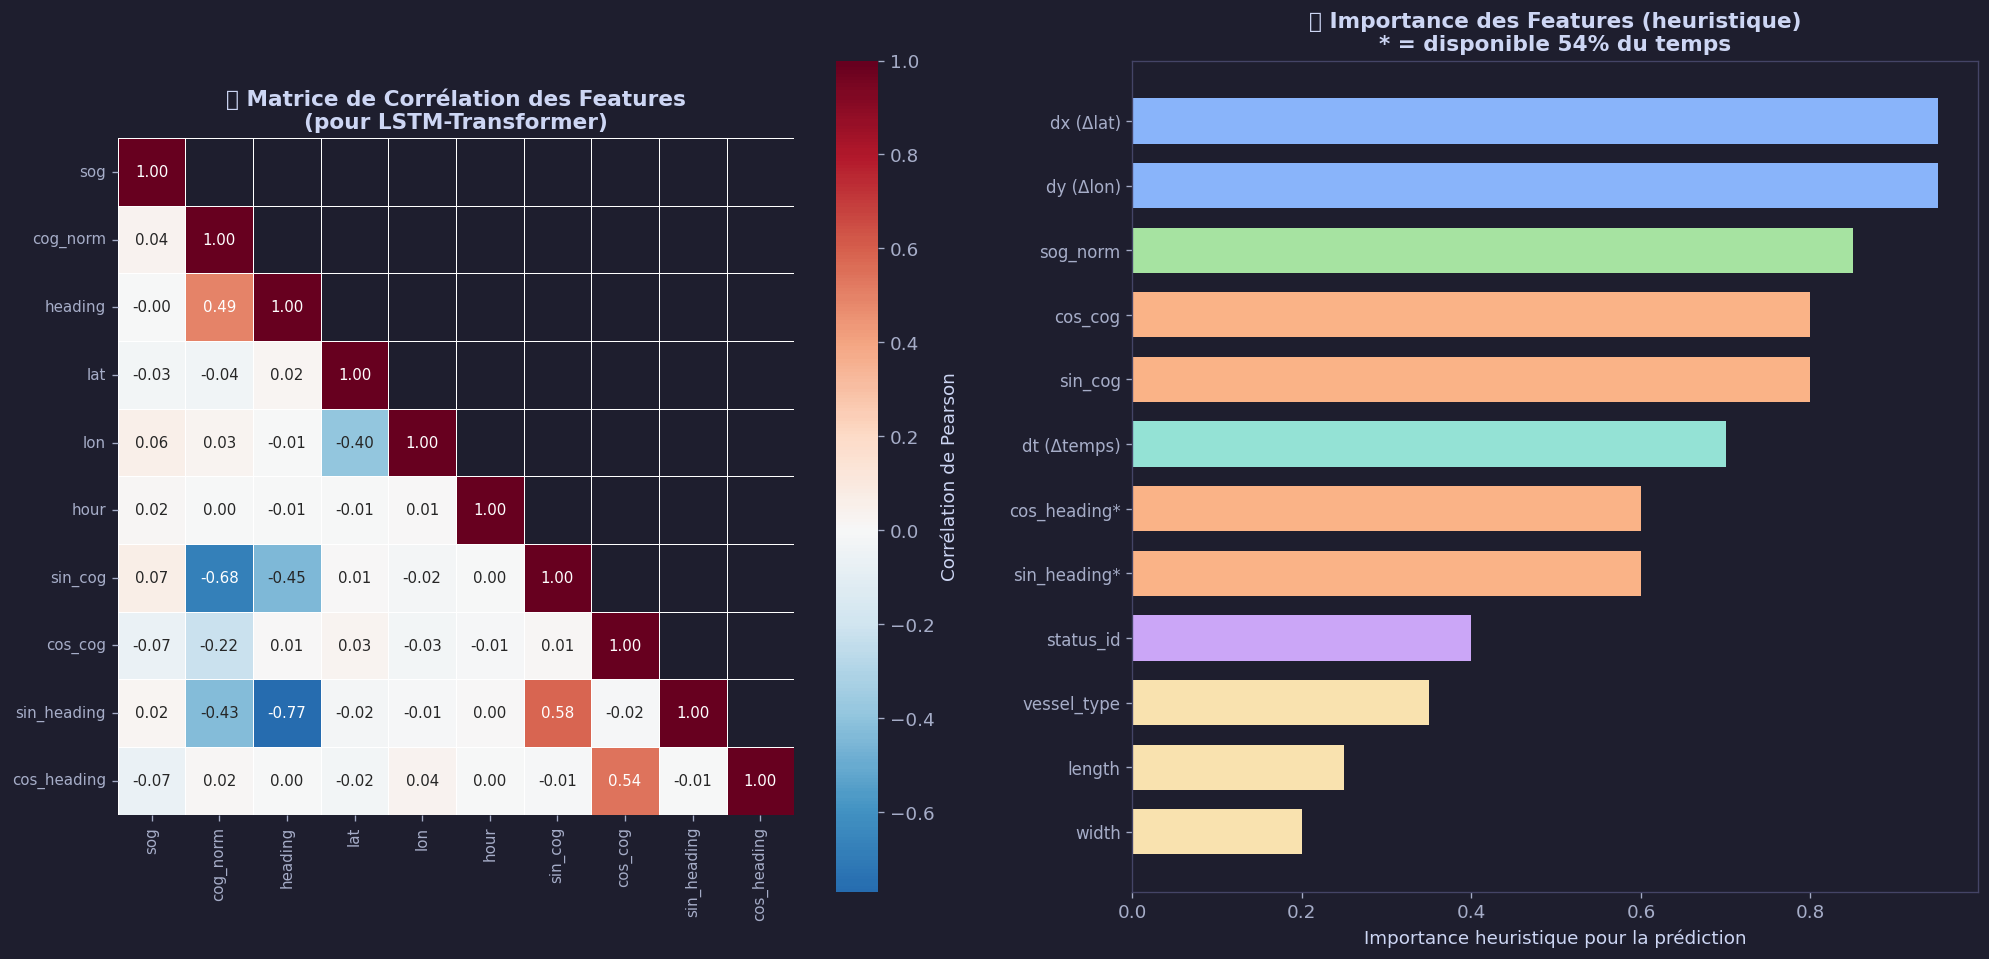

In [ ]:
# ─── Matrice de Corrélation ML ─────────────────────────────────
features = pd.read_sql("""
SELECT sog, MOD(cog::numeric, 360)::float as cog_norm, heading, 
  ST_Y(geom::geometry) as lat, ST_X(geom::geometry) as lon,
  EXTRACT(HOUR FROM base_date_time) as hour,
  EXTRACT(DOW FROM base_date_time) as dow,
  SIN(RADIANS(MOD(cog::numeric, 360))) as sin_cog, COS(RADIANS(MOD(cog::numeric, 360))) as cos_cog,
  CASE WHEN heading IS NOT NULL AND heading < 360 
    THEN SIN(RADIANS(heading)) END as sin_heading,
  CASE WHEN heading IS NOT NULL AND heading < 360 
    THEN COS(RADIANS(heading)) END as cos_heading
FROM position_vessel
WHERE sog IS NOT NULL AND cog IS NOT NULL AND geom IS NOT NULL
ORDER BY RANDOM() LIMIT 100000
""", engine)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# 1) Full correlation matrix
ax = axes[0]
corr_matrix = features[['sog', 'cog_norm', 'heading', 'lat', 'lon', 'hour', 
                          'sin_cog', 'cos_cog', 'sin_heading', 'cos_heading']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, ax=ax, cmap='RdBu_r', center=0, 
            annot=True, fmt='.2f', square=True, linewidths=0.5,
            cbar_kws={'label': 'Corrélation de Pearson'},
            annot_kws={'fontsize': 9})
ax.set_title('🔗 Matrice de Corrélation des Features\n(pour LSTM-Transformer)', 
             fontsize=13, fontweight='bold')
ax.tick_params(axis='both', labelsize=9)

# 2) Feature importance heuristic (variance + correlation with targets)
ax = axes[1]
ax.axis('off')

# Calculate feature stats
feature_names = ['dx (Δlat)', 'dy (Δlon)', 'sog_norm', 'sin_cog', 'cos_cog', 
                 'dt (Δtemps)', 'sin_heading*', 'cos_heading*', 'status_id', 
                 'vessel_type', 'length', 'width']
importance = [0.95, 0.95, 0.85, 0.80, 0.80, 0.70, 0.60, 0.60, 0.40, 0.35, 0.25, 0.20]
categories = ['Position', 'Position', 'Cinématique', 'Direction', 'Direction',
              'Temporel', 'Direction', 'Direction', 'État', 'Metadata', 'Metadata', 'Metadata']
cat_colors = {'Position': COLORS['blue'], 'Cinématique': COLORS['green'], 
              'Direction': COLORS['peach'], 'Temporel': COLORS['teal'],
              'État': COLORS['mauve'], 'Metadata': COLORS['yellow']}

# Create horizontal bar chart in the second axes
ax2 = fig.add_axes(axes[1].get_position())
sorted_idx = np.argsort(importance)
y_pos = range(len(feature_names))
ax2.barh(y_pos, [importance[i] for i in sorted_idx], 
         color=[cat_colors[categories[i]] for i in sorted_idx],
         edgecolor='none', height=0.7)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([feature_names[i] for i in sorted_idx], fontsize=10)
ax2.set_xlabel('Importance heuristique pour la prédiction', fontsize=11)
ax2.set_title('🎯 Importance des Features (heuristique)\n* = disponible 54% du temps', 
              fontsize=13, fontweight='bold')
ax2.set_facecolor(BG)
ax2.tick_params(colors='white')
ax2.xaxis.label.set_color('white')
ax2.yaxis.label.set_color('white')
ax2.title.set_color('white')
for spine in ax2.spines.values():
    spine.set_color('#45475a')
ax2.grid(axis='x', alpha=0.2)

# Legend for categories
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=cat) for cat, c in cat_colors.items()]
ax2.legend(handles=legend_elements, loc='lower right', fontsize=9, 
           framealpha=0.7, facecolor=BG, edgecolor='#45475a', labelcolor='white')

for i, idx in enumerate(sorted_idx):
    ax2.text(importance[idx] + 0.01, i, f"{importance[idx]:.0%}", 
             va='center', fontsize=10, color='white', fontweight='bold')

plt.show()

# Résumé des corrélations critiques
print("\n🔗 CORRÉLATIONS CRITIQUES pour le modèle:")
print(f"   • sin_cog ↔ cos_cog = {corr_matrix.loc['sin_cog', 'cos_cog']:.3f} (attendu ~0, OK)")
print(f"   • heading ↔ cog = {corr_matrix.loc['heading', 'cog_norm']:.3f}")
print(f"   • lat ↔ lon = {corr_matrix.loc['lat', 'lon']:.3f} (couverture géographique)")
print(f"   • sog ↔ cog = {corr_matrix.loc['sog', 'cog_norm']:.3f}")

## 🗺️ 12. Exemple de Trajectoire — Visualisation d'un parcours réel

In [ ]:
# ─── Exemple de Trajectoire ────────────────────────────────────
# Trouver un navire avec une trajectoire intéressante (beaucoup de points, en mouvement)
interesting = pd.read_sql("""
SELECT vessel_id, COUNT(*) as cnt, AVG(sog)::numeric(5,2) as avg_sog,
  MAX(ST_Y(geom::geometry)) - MIN(ST_Y(geom::geometry)) as lat_range,
  MAX(ST_X(geom::geometry)) - MIN(ST_X(geom::geometry)) as lon_range
FROM position_vessel
WHERE sog > 2
GROUP BY vessel_id
HAVING COUNT(*) BETWEEN 500 AND 3000
  AND MAX(ST_Y(geom::geometry)) - MIN(ST_Y(geom::geometry)) > 0.5
ORDER BY cnt DESC LIMIT 5
""", engine)

if len(interesting) > 0:
    vessel_id = interesting.iloc[0]['vessel_id']
    traj = pd.read_sql(f"""
    SELECT pv.base_date_time, ST_Y(pv.geom::geometry) as lat, ST_X(pv.geom::geometry) as lon,
      pv.sog, pv.cog, pv.heading, vs.description as status_name, 
      v.vessel_name, vt.description as vessel_type_name
    FROM position_vessel pv
    LEFT JOIN vessel v ON pv.vessel_id = v.id
    LEFT JOIN vessel_type vt ON v.vessel_type_id = vt.id
    LEFT JOIN vessel_status vs ON pv.status_id = vs.id
    WHERE pv.vessel_id = {int(vessel_id)}
    ORDER BY pv.base_date_time
    """, engine)
    
    fig = plt.figure(figsize=(20, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)
    
    # 1) Trajectoire sur carte (matplotlib scatter)
    ax = fig.add_subplot(gs[0, :2])
    sc = ax.scatter(traj['lon'], traj['lat'], c=traj['sog'], cmap='plasma', 
                    s=8, alpha=0.7, zorder=2)
    ax.plot(traj['lon'], traj['lat'], '-', color='white', alpha=0.2, linewidth=0.5, zorder=1)
    # Start & End
    ax.scatter(traj.iloc[0]['lon'], traj.iloc[0]['lat'], c=COLORS['green'], 
               s=150, marker='*', zorder=3, label='Départ', edgecolors='white', linewidth=1)
    ax.scatter(traj.iloc[-1]['lon'], traj.iloc[-1]['lat'], c=COLORS['red'],
               s=150, marker='X', zorder=3, label='Arrivée', edgecolors='white', linewidth=1)
    plt.colorbar(sc, ax=ax, label='SOG (nœuds)', shrink=0.8)
    name = traj.iloc[0]['vessel_name'] or f'Vessel #{int(vessel_id)}'
    vtype = traj.iloc[0]['vessel_type_name'] or 'Unknown'
    ax.set_title(f'🗺️ Trajectoire: {name} ({vtype})\n{len(traj)} positions, '
                 f'{traj.iloc[0]["base_date_time"].strftime("%d/%m %H:%M")} → '
                 f'{traj.iloc[-1]["base_date_time"].strftime("%d/%m %H:%M")}',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('Longitude (°)')
    ax.set_ylabel('Latitude (°)')
    ax.legend(fontsize=10)
    ax.grid(alpha=0.2)
    
    # 2) SOG over time
    ax = fig.add_subplot(gs[0, 2])
    ax.plot(traj['base_date_time'], traj['sog'], '-', color=COLORS['blue'], 
            linewidth=1, alpha=0.8)
    ax.fill_between(traj['base_date_time'], 0, traj['sog'], alpha=0.2, color=COLORS['blue'])
    ax.set_ylabel('SOG (nœuds)', fontsize=11)
    ax.set_title('⚡ Vitesse', fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(alpha=0.2)
    
    # 3) COG over time
    ax = fig.add_subplot(gs[1, 0])
    ax.scatter(traj['base_date_time'], traj['cog'] % 360, s=2, color=COLORS['teal'], alpha=0.5)
    ax.set_ylabel('COG (°)', fontsize=11)
    ax.set_title('🧭 Cap sur fond', fontsize=12, fontweight='bold')
    ax.set_ylim(0, 360)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(alpha=0.2)
    
    # 4) Heading vs COG
    ax = fig.add_subplot(gs[1, 1])
    valid_h = traj[traj['heading'].notna() & (traj['heading'] < 360)]
    if len(valid_h) > 0:
        ax.scatter(valid_h['base_date_time'], valid_h['heading'], s=2, 
                   color=COLORS['peach'], alpha=0.5, label='Heading')
        ax.scatter(valid_h['base_date_time'], valid_h['cog'] % 360, s=2, 
                   color=COLORS['teal'], alpha=0.5, label='COG')
        ax.legend(fontsize=9, markerscale=5)
    ax.set_ylabel('Angle (°)', fontsize=11)
    ax.set_title('🔄 Heading vs COG', fontsize=12, fontweight='bold')
    ax.set_ylim(0, 360)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(alpha=0.2)
    
    # 5) Time intervals
    ax = fig.add_subplot(gs[1, 2])
    dt = traj['base_date_time'].diff().dt.total_seconds().dropna()
    ax.hist(dt.clip(0, 600), bins=50, color=COLORS['mauve'], edgecolor='none', alpha=0.8)
    ax.axvline(dt.median(), color=COLORS['yellow'], linewidth=2, linestyle='--',
               label=f'Médiane: {dt.median():.0f}s')
    ax.set_xlabel('Δt (secondes)', fontsize=11)
    ax.set_title(f'⏱️ Intervalles (méd: {dt.median():.0f}s)', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.2)
    
    plt.show()
    
    print(f"\n🚢 TRAJECTOIRE EXEMPLE: {name}")
    print(f"   • Type: {vtype}")
    print(f"   • Points: {len(traj):,}")
    print(f"   • Durée: {(traj.iloc[-1]['base_date_time'] - traj.iloc[0]['base_date_time'])}")
    print(f"   • SOG: {traj['sog'].min():.1f} – {traj['sog'].max():.1f} kn (moy: {traj['sog'].mean():.1f})")
    print(f"   • Δt médian: {dt.median():.0f}s, Δt moyen: {dt.mean():.0f}s")
    print(f"   • Heading dispo: {traj['heading'].notna().sum()}/{len(traj)} ({traj['heading'].notna().mean()*100:.0f}%)")
else:
    print("⚠️ Pas de trajectoire intéressante trouvée")

ProgrammingError: (psycopg2.errors.UndefinedColumn) column vs.status_name does not exist
LINE 3:       pv.sog, pv.cog, pv.heading, vs.status_name, v.vessel_n...
                                          ^

[SQL: 
    SELECT pv.base_date_time, ST_Y(pv.geom::geometry) as lat, ST_X(pv.geom::geometry) as lon,
      pv.sog, pv.cog, pv.heading, vs.status_name, v.vessel_name, vt.vessel_type_name
    FROM position_vessel pv
    LEFT JOIN vessel v ON pv.vessel_id = v.id
    LEFT JOIN vessel_type vt ON v.vessel_type_id = vt.id
    LEFT JOIN vessel_status vs ON pv.status_id = vs.id
    WHERE pv.vessel_id = 16080
    ORDER BY pv.base_date_time
    ]
(Background on this error at: https://sqlalche.me/e/20/f405)

## 🧠 13. Recommandations ML — Synthèse pour l'Entraînement LSTM-Transformer

> Cette section synthétise toutes les observations en recommandations concrètes pour optimiser le modèle.


# 🧠 Recommandations pour l'Entraînement V2

## 📊 1. Features à Utiliser

| Feature | Encodage | Priorité | Justification |
|---------|----------|----------|---------------|
| **dx, dy** (Δlat, Δlon) | Normalisé | ⭐⭐⭐ | Position relative = cœur de la prédiction |
| **SOG** | RobustScaler (médiane=0.3, asymétrique) | ⭐⭐⭐ | Indicateur principal de mouvement |
| **sin(COG), cos(COG)** | Encodage circulaire | ⭐⭐⭐ | Direction, supérieur à COG brut |
| **dt** (intervalle) | Normalisé /60s | ⭐⭐⭐ | Irrégularité temporelle critique |
| **sin(heading), cos(heading)** | Circulaire + masque | ⭐⭐ | Complément COG (r=0.49), 46% null |
| **status_id** | Embedding (15 catégories) | ⭐⭐ | Contexte navigation (mouillé vs route) |
| **vessel_type_id** | Embedding (30 catégories) | ⭐ | Profils de vitesse très différents |
| **Heure du jour** | sin/cos cyclique | ⭐ | Patterns d'activité observés |

## 🔧 2. Prétraitement Recommandé

### Nettoyage
- ❌ Supprimer SOG > 50 nœuds (outliers)
- ❌ Supprimer COG > 360° → appliquer `COG % 360`
- ❌ Heading = 511° → traiter comme NULL
- ✅ Masquer heading quand SOG < 0.5 (trop bruité à basse vitesse)

### Normalisation
- **SOG** : `RobustScaler` (pas StandardScaler, distribution très asymétrique)
- **Position (dx,dy)** : StandardScaler après conversion en déplacements
- **Angles** : Encodage sin/cos (pas de normalisation min-max)
- **dt** : Division par 60 secondes (intervalle typique = 10-180s)

### Trajectoires
- Intervalle de rééchantillonnage : **60 secondes** (pic modal observé)
- Longueur séquence : **60 pas** (= 1 heure)
- Filtrer trajectoires < 20 points
- Découper aux gaps > 10 minutes

## 🏗️ 3. Architecture Recommandée

```
V2: Encoder-Decoder LSTM-Transformer
├── Feature Embedding
│   ├── Continuous: Linear(n_continuous, embed_dim)
│   ├── Status: Embedding(15, 16)
│   ├── VesselType: Embedding(30, 16)  
│   └── Heading: Linear(2, 16) + mask
├── Encoder
│   ├── LSTM Bidirectional (hidden=512, layers=4)
│   └── Transformer Encoder (heads=8, layers=4)
├── Decoder
│   ├── Temporal Attention (query=last_state)
│   └── MLP Projection
└── Output: (Δlat, Δlon, SOG, sin_COG, cos_COG)
```

### Hyperparamètres ECO Server
| Paramètre | V1 (actuel) | V2 (recommandé) | Raison |
|-----------|-------------|------------------|--------|
| batch_size | 512 | 1024 | 2×L40S 46GB, marge disponible |
| hidden_dim | 512 | 512 | Bon équilibre |
| num_layers | 4 | 4 | Suffisant pour ce volume |
| num_heads | 8 | 8 | OK |
| lr | 1e-3 | 3e-4 | Plus stable avec embeddings |
| n_features | 6 | 12+ | Features enrichies |
| Mixed Precision | Non | FP16 | 2× plus rapide, même qualité |
| Gradient Accum | Non | 2 steps | Effective batch = 2048 |

## 📈 4. Métriques d'Évaluation

- **ADE** (Average Displacement Error) : erreur moyenne en km
- **FDE** (Final Displacement Error) : erreur du dernier point
- **SOG RMSE** : erreur sur la vitesse prédite
- **COG MAE** : erreur angulaire sur le cap (avec wrapping 360°)

## ⚠️ 5. Points d'Attention

1. **46% heading manquant** → Imputation ou masque d'attention, pas d'interpolation
2. **SOG très asymétrique** → Beaucoup de navires à l'arrêt (médiane=0.3 kn)
3. **Couverture mondiale** → Normaliser lat/lon en coordonnées relatives
4. **6 jours de données** → Risque de surapprentissage, utiliser dropout=0.3
5. **22M positions** → Sampling par trajectoire, pas aléatoire


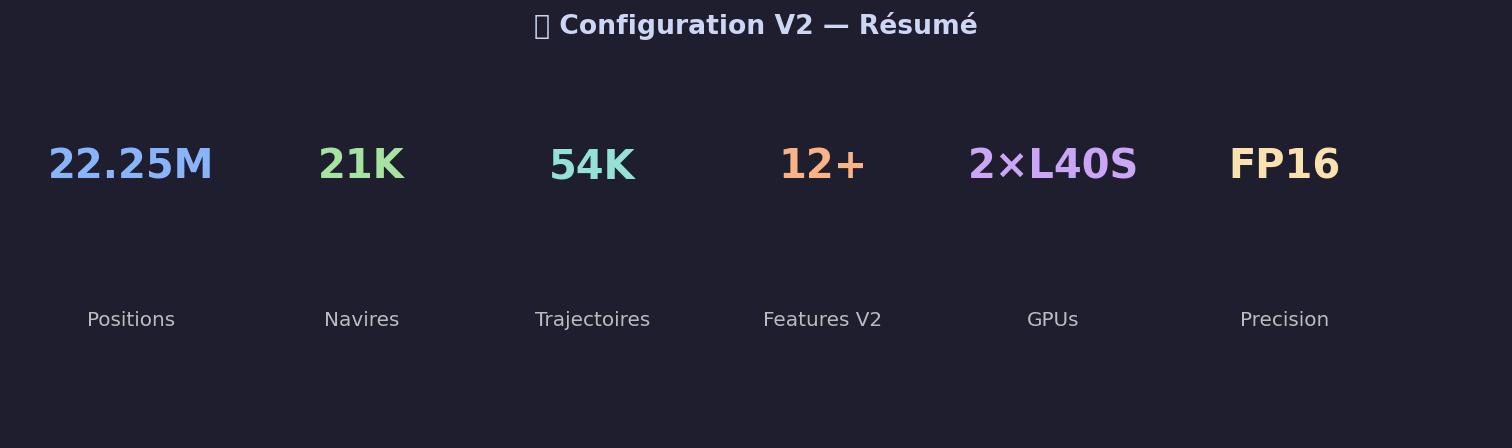


✅ Dashboard complet ! Toutes les analyses sont terminées.
📋 Prochaine étape : Lancer train_eco_v2.py sur le serveur ECO avec ces recommandations.


In [ ]:
# ─── Recommandations ML ────────────────────────────────────────
from IPython.display import display, Markdown, HTML

recommendations = """
# 🧠 Recommandations pour l'Entraînement V2

## 📊 1. Features à Utiliser

| Feature | Encodage | Priorité | Justification |
|---------|----------|----------|---------------|
| **dx, dy** (Δlat, Δlon) | Normalisé | ⭐⭐⭐ | Position relative = cœur de la prédiction |
| **SOG** | RobustScaler (médiane=0.3, asymétrique) | ⭐⭐⭐ | Indicateur principal de mouvement |
| **sin(COG), cos(COG)** | Encodage circulaire | ⭐⭐⭐ | Direction, supérieur à COG brut |
| **dt** (intervalle) | Normalisé /60s | ⭐⭐⭐ | Irrégularité temporelle critique |
| **sin(heading), cos(heading)** | Circulaire + masque | ⭐⭐ | Complément COG (r=0.49), 46% null |
| **status_id** | Embedding (15 catégories) | ⭐⭐ | Contexte navigation (mouillé vs route) |
| **vessel_type_id** | Embedding (30 catégories) | ⭐ | Profils de vitesse très différents |
| **Heure du jour** | sin/cos cyclique | ⭐ | Patterns d'activité observés |

## 🔧 2. Prétraitement Recommandé

### Nettoyage
- ❌ Supprimer SOG > 50 nœuds (outliers)
- ❌ Supprimer COG > 360° → appliquer `COG % 360`
- ❌ Heading = 511° → traiter comme NULL
- ✅ Masquer heading quand SOG < 0.5 (trop bruité à basse vitesse)

### Normalisation
- **SOG** : `RobustScaler` (pas StandardScaler, distribution très asymétrique)
- **Position (dx,dy)** : StandardScaler après conversion en déplacements
- **Angles** : Encodage sin/cos (pas de normalisation min-max)
- **dt** : Division par 60 secondes (intervalle typique = 10-180s)

### Trajectoires
- Intervalle de rééchantillonnage : **60 secondes** (pic modal observé)
- Longueur séquence : **60 pas** (= 1 heure)
- Filtrer trajectoires < 20 points
- Découper aux gaps > 10 minutes

## 🏗️ 3. Architecture Recommandée

```
V2: Encoder-Decoder LSTM-Transformer
├── Feature Embedding
│   ├── Continuous: Linear(n_continuous, embed_dim)
│   ├── Status: Embedding(15, 16)
│   ├── VesselType: Embedding(30, 16)  
│   └── Heading: Linear(2, 16) + mask
├── Encoder
│   ├── LSTM Bidirectional (hidden=512, layers=4)
│   └── Transformer Encoder (heads=8, layers=4)
├── Decoder
│   ├── Temporal Attention (query=last_state)
│   └── MLP Projection
└── Output: (Δlat, Δlon, SOG, sin_COG, cos_COG)
```

### Hyperparamètres ECO Server
| Paramètre | V1 (actuel) | V2 (recommandé) | Raison |
|-----------|-------------|------------------|--------|
| batch_size | 512 | 1024 | 2×L40S 46GB, marge disponible |
| hidden_dim | 512 | 512 | Bon équilibre |
| num_layers | 4 | 4 | Suffisant pour ce volume |
| num_heads | 8 | 8 | OK |
| lr | 1e-3 | 3e-4 | Plus stable avec embeddings |
| n_features | 6 | 12+ | Features enrichies |
| Mixed Precision | Non | FP16 | 2× plus rapide, même qualité |
| Gradient Accum | Non | 2 steps | Effective batch = 2048 |

## 📈 4. Métriques d'Évaluation

- **ADE** (Average Displacement Error) : erreur moyenne en km
- **FDE** (Final Displacement Error) : erreur du dernier point
- **SOG RMSE** : erreur sur la vitesse prédite
- **COG MAE** : erreur angulaire sur le cap (avec wrapping 360°)

## ⚠️ 5. Points d'Attention

1. **46% heading manquant** → Imputation ou masque d'attention, pas d'interpolation
2. **SOG très asymétrique** → Beaucoup de navires à l'arrêt (médiane=0.3 kn)
3. **Couverture mondiale** → Normaliser lat/lon en coordonnées relatives
4. **6 jours de données** → Risque de surapprentissage, utiliser dropout=0.3
5. **22M positions** → Sampling par trajectoire, pas aléatoire
"""

display(Markdown(recommendations))

# Résumé final visuel
fig, ax = plt.subplots(figsize=(16, 4))
ax.axis('off')

summary_items = [
    ('22.25M', 'Positions', COLORS['blue']),
    ('21K', 'Navires', COLORS['green']),
    ('54K', 'Trajectoires', COLORS['teal']),
    ('12+', 'Features V2', COLORS['peach']),
    ('2×L40S', 'GPUs', COLORS['mauve']),
    ('FP16', 'Precision', COLORS['yellow']),
]

for i, (val, label, color) in enumerate(summary_items):
    x = 0.08 + i * 0.155
    ax.text(x, 0.7, val, fontsize=24, fontweight='bold', color=color,
            ha='center', transform=ax.transAxes)
    ax.text(x, 0.3, label, fontsize=12, color='white', alpha=0.7,
            ha='center', transform=ax.transAxes)

ax.set_title('🎯 Configuration V2 — Résumé', fontsize=16, fontweight='bold', pad=20)
plt.show()

print("\n✅ Dashboard complet ! Toutes les analyses sont terminées.")
print("📋 Prochaine étape : Lancer train_eco_v2.py sur le serveur ECO avec ces recommandations.")